# Initialisation

## 📖 required libraries

In [1]:
# Python librairies
import numpy as np
import pandas as pd

from collections import defaultdict, deque

# For plots
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D


# For chemical element recognition, we can use the mendeleev library to get a list of valid chemical symbols.
# !pip install mendeleev # Uncomment this line to install mendeleev if it's not already installed
from mendeleev import element as mendeleev_element # Importing the element function from mendeleev

## 🚴 your local paths

In [2]:
# input path
file_path = "" #/old
excel_file_path = f"{file_path}sea.xlsx"
print(excel_file_path)

sea.xlsx


In [ ]:
# Shared figure style and export helpers (figure_style.py in the repo root)
import os
import sys

sys.path.append(os.path.abspath(".."))

from figure_style import (
    ELEMENT_COLORS,
    PROCESS_COLORS,
    REST_COLOR,
    RSE_COLOR,
    SCENARIO_COLORS,
    SE_COLOR,
    apply_style,
    get_element_color,
    get_process_color,
    save_figure,
)

RESULTS_DIR = "results"  # figures are exported to <notebook folder>/results
os.makedirs(RESULTS_DIR, exist_ok=True)
apply_style()


## information element formalism: the chemical elements

In [3]:
# Function 'is_chemical_element' to check if a name is a chemical element for Statistical Entropy.
# Modified to also recognize "Rest" as a valid component.
# 1. Is used in the mass balance checking function for the process simulated input data.
# 
try:
    def is_chemical_element(name):
        # Special case: "Rest" is treated like an element for entropy calculations
        if name == "Rest":
            return True
        
        if len(name) <= 2 and name.isalpha():
            try:
                mendeleev_element(name)
                return True
            except:
                return False
        return False
except ImportError:
    # Fallback: use common chemical symbols if mendeleev not available
    chemical_symbols = {
        'H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar',
        'K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr',
        'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe',
        'Cs', 'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu',
        'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn',
        'Fr', 'Ra', 'Ac', 'Th', 'Pa', 'U', 'Np', 'Pu', 'Am', 'Cm', 'Bk', 'Cf', 'Es', 'Fm', 'Md', 'No', 'Lr'
    }
    
    def is_chemical_element(name):
        # Special case: "Rest" is treated like an element for entropy calculations
        if name == "Rest":
            return True
        
        return 1 <= len(name) <= 2 and name in chemical_symbols

In [4]:
df = pd.read_excel(excel_file_path)
            
# Clean column names (remove extra spaces)
df.columns = df.columns.str.strip()

# Identify element columns (they should be the ones after "Mass Flow Rate (t/h)")
all_columns = df.columns.tolist()
mass_flow_col = 'mass-FU_kg-eq' # oldversion: "Mass Flow Rate (t/h)" # newversion: "mass-FU_kg-eq"
mass_flow_idx = all_columns.index(mass_flow_col)

# Assuming element columns are all columns after the mass flow column, we can filter them using the is_chemical_element function
element_columns = [col for col in all_columns if is_chemical_element(col)]
element_columns        

['Al',
 'C',
 'Ca',
 'Co',
 'Cu',
 'F',
 'Fe',
 'H',
 'Li',
 'Mn',
 'Na',
 'Ni',
 'O',
 'P',
 'S']

## ⚖️ Unit Processes elemental-mass balance

In [5]:
import pandas as pd
import numpy as np

def check_mass_balance_per_element(excel_file):
    """
    Check mass balance for each sheet in an Excel file with detailed element-wise analysis
    
    Parameters:
    excel_file (str): Path to the Excel file
    
    Returns:
    dict: Dictionary with sheet names as keys and detailed mass balance DataFrames as values
    """
    
    # Read all sheet names
    xl = pd.ExcelFile(excel_file)
    sheet_names = xl.sheet_names
    
    results = {}
    
    for sheet_name in sheet_names:
        try:
            # Read the sheet
            df = pd.read_excel(excel_file, sheet_name=sheet_name)
            
            # Clean column names (remove extra spaces)
            df.columns = df.columns.str.strip()
            
            # Identify element columns (they should be the ones after "Mass Flow Rate (t/h)")
            all_columns = df.columns.tolist()
            mass_flow_col = 'mass-FU_kg-eq' # oldversion: "Mass Flow Rate (t/h)" # newversion: "mass-FU_kg-eq"
            mass_flow_idx = all_columns.index(mass_flow_col)
            
            # Assuming element columns are all columns after the mass flow column, we can filter them using the is_chemical_element function
            element_columns = [col for col in all_columns if is_chemical_element(col)]
            # Separate Inputs and Outputs (excluding total rows)
            inputs_mask = (df['direction'] == 'input') & (~df['flow_name'].str.contains('total', case=False, na=False)) # 'Sens' can replace 'direction' in the previous versions
            outputs_mask = (df['direction'] == 'output') & (~df['flow_name'].str.contains('total', case=False, na=False))
            
            inputs = df[inputs_mask].copy()
            outputs = df[outputs_mask].copy()
            
            # Calculate element mass flows (mass flow rate * concentration / 100) because concentration are noted in w%
            for element in element_columns:
                inputs[f'{element}_mass'] = inputs[mass_flow_col] * inputs[element] / 100
                outputs[f'{element}_mass'] = outputs[mass_flow_col] * outputs[element] / 100
            
            # Create detailed mass balance DataFrame per element
            mass_balance_data = []
            
            for element in element_columns:
                # Input details
                input_flows = inputs[inputs[element] > 0]  # Only flows containing this element
                input_mass_per_flow = input_flows[mass_flow_col] * input_flows[element] / 100
                total_input = input_mass_per_flow.sum()
                
                # Output details
                output_flows = outputs[outputs[element] > 0]  # Only flows containing this element
                output_mass_per_flow = output_flows[mass_flow_col] * output_flows[element] / 100
                total_output = output_mass_per_flow.sum()
                
                # Balance calculations
                balance = total_input - total_output
                relative_error = (balance / total_input * 100) if total_input != 0 else np.nan
                
                # Input flow contributions
                input_contributions = []
                for idx, row in input_flows.iterrows():
                    if row[element] > 0:  # Only include flows with this element
                        mass_contribution = row[mass_flow_col] * row[element] / 100
                        percentage = (mass_contribution / total_input * 100) if total_input != 0 else 0
                        input_contributions.append(
                            f"{row['flow_name']}: {mass_contribution*1000:.3f} kg/h ({percentage:.1f}%)"
                        )
                
                # Output flow contributions
                output_contributions = []
                for idx, row in output_flows.iterrows():
                    if row[element] > 0:  # Only include flows with this element
                        mass_contribution = row[mass_flow_col] * row[element] / 100
                        percentage = (mass_contribution / total_output * 100) if total_output != 0 else 0
                        output_contributions.append(
                            f"{row['flow_name']}: {mass_contribution:.3f} kg/h ({percentage:.1f}%)"
                        )
                
                mass_balance_data.append({
                    'Element': element,
                    'Total Input (kg/h)': total_input * 1000,
                    'Total Output (kg/h)': total_output * 1000,
                    'Balance (kg/h)': balance * 1000,
                    'Relative Error (%)': relative_error,
                    'Input Flows': "\n".join(input_contributions) if input_contributions else "None",
                    'Output Flows': "\n".join(output_contributions) if output_contributions else "None",
                    'Input Flow Count': len(input_contributions),
                    'Output Flow Count': len(output_contributions)
                })
            
            # Create the mass balance DataFrame
            mass_balance_df = pd.DataFrame(mass_balance_data)
            
            # Sort by absolute balance magnitude (largest imbalances first)
            mass_balance_df['Abs_Balance'] = mass_balance_df['Balance (kg/h)'].abs()
            mass_balance_df = mass_balance_df.sort_values('Abs_Balance', ascending=False).drop('Abs_Balance', axis=1)
            
            # Calculate overall mass balance
            total_input_mass = inputs[mass_flow_col].sum()
            total_output_mass = outputs[mass_flow_col].sum()
            total_balance = total_input_mass - total_output_mass
            total_relative_error = (total_balance / total_input_mass * 100) if total_input_mass != 0 else np.nan
            
            # Add summary statistics
            summary_stats = {
                'Process': sheet_name,
                'Total Input Mass (t/h)': total_input_mass,
                'Total Output Mass (t/h)': total_output_mass,
                'Mass Balance Error (t/h)': total_balance,
                'Relative Error (%)': total_relative_error,
                'Elements with Imbalance > 1%': len(mass_balance_df[mass_balance_df['Relative Error (%)'].abs() > 1]),
                'Elements Analyzed': len(element_columns)
            }
            
            results[sheet_name] = {
                'detailed_balance': mass_balance_df,
                'summary': summary_stats,
                'element_columns': element_columns
            }
            
            # Print summary
            print(f"=== MASS BALANCE ANALYSIS FOR: {sheet_name} ===")
            print(f"Total input mass: {total_input_mass:.4f} t/h")
            print(f"Total output mass: {total_output_mass:.4f} t/h")
            print(f"Overall mass balance: {total_balance:.6f} t/h")
            print(f"Overall relative error: {total_relative_error:.4f}%")
            print(f"Elements analyzed: {len(element_columns)}")
            print("\nTop 5 elements with largest imbalances:")
            
            top_imbalances = mass_balance_df.head(5)
            for _, row in top_imbalances.iterrows():
                print(f"  {row['Element']}: {row['Balance (kg/h)']:+.3f} kg/h ({row['Relative Error (%)']:+.2f}%)")
            
            print("=" * 60)
            
        except Exception as e:
            print(f"Error processing sheet {sheet_name}: {str(e)}")
            results[sheet_name] = None
    
    return results

def export_mass_balance_results(results, output_file):
    """
    Export mass balance results to Excel file with multiple sheets
    """
    with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
        for sheet_name, data in results.items():
            if data is not None:
                # Write detailed balance sheet
                data['detailed_balance'].to_excel(writer, sheet_name=f"{sheet_name}_balance", index=False)
                
                # Write summary sheet
                summary_df = pd.DataFrame([data['summary']])
                summary_df.to_excel(writer, sheet_name=f"{sheet_name}_summary", index=False)

# Usage example
if __name__ == "__main__":
    
    # Get mass balance results
    mass_balance_results = check_mass_balance_per_element(excel_file_path)
    
    # Export to Excel
    export_mass_balance_results(mass_balance_results, f"{file_path}mass_balance_results.xlsx")
    

=== MASS BALANCE ANALYSIS FOR: u1_black-mass-pulping ===
Total input mass: 1.5810 t/h
Total output mass: 1.5820 t/h
Overall mass balance: -0.001000 t/h
Overall relative error: -0.0633%
Elements analyzed: 15

Top 5 elements with largest imbalances:
  F: -0.409 kg/h (-1.33%)
  O: -0.398 kg/h (-0.06%)
  H: -0.058 kg/h (-0.11%)
  C: -0.042 kg/h (-0.01%)
  Ni: -0.033 kg/h (-0.01%)
=== MASS BALANCE ANALYSIS FOR: u2_leaching ===
Total input mass: 8.1760 t/h
Total output mass: 8.1760 t/h
Overall mass balance: 0.000000 t/h
Overall relative error: 0.0000%
Elements analyzed: 15

Top 5 elements with largest imbalances:
  O: -0.073 kg/h (-0.00%)
  S: -0.059 kg/h (-0.00%)
  Ni: +0.032 kg/h (+0.01%)
  H: -0.026 kg/h (-0.01%)
  Li: +0.021 kg/h (+0.05%)
=== MASS BALANCE ANALYSIS FOR: u3_hydrated-lime_pulping ===
Total input mass: 1.7820 t/h
Total output mass: 1.7820 t/h
Overall mass balance: 0.000000 t/h
Overall relative error: 0.0000%
Elements analyzed: 15

Top 5 elements with largest imbalances:
  Ca

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\openpyxl\workbook\child.py:99: UserWarning: Title is more than 31 characters. Some applications may not be able to read the file
  warnings.warn("Title is more than 31 characters. Some applications may not be able to read the file")


# Stage diagram construction

## functions

### get the original process(es) candidate(s)

In [6]:
def get_original_processes(excel_file):
    """
    Return list of original processes (root nodes).
    1. Processes with "fu" in any input provider
    2. Processes with no process inputs
    """
    xl = pd.ExcelFile(excel_file)
    sheet_names = xl.sheet_names
    all_processes = set(sheet_names)
    
    original_processes = []
    
    for process in sheet_names:
        df = pd.read_excel(excel_file, sheet_name=process)
        df.columns = df.columns.str.strip()
        
        has_fu = False
        has_process_input = False
        
        for _, row in df.iterrows():
            direction = str(row.get("direction", "")).strip().lower()
            provider = str(row.get("provider/consumer", "")).strip()
            
            if direction == "input":
                if "fu" in provider.lower(): # if the system modelled aims to recycle a certain amount of flow, the first stage should be the one that import the waste flow to be treated
                    has_fu = True
                if provider in all_processes:
                    has_process_input = True # if the process has at least one process input, it is not an original process, except if it also has a "fu" input
        
        if has_fu or not has_process_input:
            original_processes.append(process)
    
    return original_processes

### processes ranking

In [7]:
def assign_process_ranks_all_options(excel_file, original_processes_list):
    """
    Assign ranks starting from EACH original process separately.
    Includes back-propagation: unranked providers get rank = min(consumer_rank) - 1.
    Returns all ranking options.
    """
    xl = pd.ExcelFile(excel_file)
    sheet_names = xl.sheet_names
    all_processes = set(sheet_names)

    # Build adjacency and store flow details (shared across all original processes)
    process_consumers = defaultdict(list)
    process_providers = defaultdict(list)
    flow_details = defaultdict(list)
    
    for sheet_name in sheet_names:
        try:
            df = pd.read_excel(excel_file, sheet_name=sheet_name)
            df.columns = df.columns.str.strip()
            
            for _, row in df.iterrows():
                flow_name = row.get("flow_name")
                flow_type = row.get("flow_type")
                consumer = row.get("provider/consumer")
                direction = row.get("direction")
                
                if pd.notna(flow_name) and pd.notna(consumer):
                    if direction == "output" and consumer in all_processes:
                        process_consumers[sheet_name].append(consumer)
                        process_providers[consumer].append(sheet_name)
                        flow_details[(sheet_name, consumer)].append({
                            "flow_name": flow_name,
                            "flow_type": flow_type,
                            "consumer": consumer
                        })
        except Exception as e:
            print(f"Error processing sheet {sheet_name}: {e}")

    # Store results for EACH original process separately
    all_rankings = {}
    
    for orig in original_processes_list:
        process_ranks = defaultdict(set)
        recycling_flows_set = set()

        # Forward BFS from original process
        queue = deque([(orig, 1)])
        
        while queue:
            current, rank = queue.popleft()

            if rank not in process_ranks[current]:
                process_ranks[current].add(rank)

            for consumer in process_consumers[current]:
                new_rank = rank + 1
                max_consumer_rank = max(process_ranks[consumer]) if process_ranks[consumer] else 0

                if max_consumer_rank and max_consumer_rank < rank:
                    for flow in flow_details.get((current, consumer), []):
                        recycling_flows_set.add((
                            current,
                            consumer,
                            flow["flow_name"],
                            flow["flow_type"]
                        ))
                    continue

                if new_rank not in process_ranks[consumer]:
                    queue.append((consumer, new_rank))

        # =====================================================================
        # NEW: Back-propagate ranks to unranked providers
        # =====================================================================
        changed = True
        while changed:
            changed = False
            for process in list(all_processes):
                if process not in process_ranks or not process_ranks[process]:
                    # This process has no rank yet
                    # Check its consumers - if any are ranked, rank this process as min(consumer_rank) - 1
                    if process in process_consumers:
                        consumer_ranks = []
                        for consumer in process_consumers[process]:
                            if consumer in process_ranks and process_ranks[consumer]:
                                consumer_ranks.append(min(process_ranks[consumer]))
                        
                        if consumer_ranks:
                            provider_rank = min(consumer_ranks) - 1
                            if provider_rank < 1:
                                provider_rank = 1  # All ranks start at 1 minimum
                            
                            if provider_rank not in process_ranks[process]:
                                process_ranks[process].add(provider_rank)
                                changed = True
            
            # Also back-propagate from newly ranked processes
            for process in list(process_ranks.keys()):
                if process_ranks[process]:
                    min_rank = min(process_ranks[process])
                    # Check providers of this process
                    for provider in process_providers.get(process, []):
                        if provider not in process_ranks or not process_ranks[provider]:
                            provider_rank = min_rank - 1
                            if provider_rank < 1:
                                provider_rank = 1
                            if provider_rank not in process_ranks[provider]:
                                process_ranks[provider].add(provider_rank)
                                changed = True
        
        # =====================================================================
        # END NEW SECTION
        # =====================================================================

        # Backfill ranks for original process
        if process_consumers[orig]:
            max_rank = max(
                (max(process_ranks[c]) for c in process_consumers[orig] if process_ranks[c]),
                default=1
            )
            if max_rank > 1:
                process_ranks[orig].update(range(1, max_rank))
        else:
            if not process_ranks[orig]:
                process_ranks[orig].add(1)

        max_rank_per_process = {p: max(ranks) for p, ranks in process_ranks.items()}
        
        recycling_flows = [
            {
                "flow_name": fn,
                "flow_type": ft,
                "producer_process": fp,
                "producer_rank": max_rank_per_process.get(fp),
                "consumer_process": tp,
                "consumer_rank": max_rank_per_process.get(tp)
            }
            for fp, tp, fn, ft in recycling_flows_set
        ]

        all_rankings[orig] = {
            "process_ranks": dict(process_ranks),
            "max_rank_per_process": max_rank_per_process,
            "recycling_flows": recycling_flows
        }
    
    return all_rankings, dict(process_consumers), dict(process_providers)


def print_all_ranking_options(all_rankings):
    """
    Print all ranking options and save each as CSV.
    Returns a list of ranking dataframes for easy access by index.
    """
    print("\n" + "="*70)
    print("ALL RANKING OPTIONS (by original process)")
    print("="*70)
    
    ranking_dfs = []  # Store dataframes for access by index
    
    for i, (orig, data) in enumerate(all_rankings.items(), 1):
        print(f"\n--- Option {i}: Starting from '{orig}' ---")
        print(f"    Number of processes ranked: {len(data['max_rank_per_process'])}")
        print(f"    Max stage: {max(data['max_rank_per_process'].values()) if data['max_rank_per_process'] else 'N/A'}")
        print(f"    Recycling flows detected: {len(data['recycling_flows'])}")
        
        # Create dataframe for this ranking
        ranking_df = pd.DataFrame.from_dict(
            data['max_rank_per_process'], 
            orient='index', 
            columns=['max_rank']
        )
        ranking_df['all_ranks'] = ranking_df.index.map(
            lambda p: sorted(data['process_ranks'][p])
        )
        ranking_df.index.name = 'process'
        ranking_df = ranking_df.reset_index()
        ranking_df['option'] = i
        ranking_df['original_process'] = orig
        
        # Save as CSV
        csv_filename = f"{file_path}ranking_option_{i}_{orig}.csv"
        ranking_df.to_csv(csv_filename, index=False)
        print(f"    → Saved: {csv_filename}")
        
        # # Show the ranking
        # for _, row in ranking_df.iterrows():
        #     print(f"      {row['process']}: ranks {row['all_ranks']} → max={row['max_rank']}")
        
        # if data['recycling_flows']:
        #     print(f"    Recycling flows:")
        #     recycling_df = pd.DataFrame(data['recycling_flows'])
        #     recycling_csv = f"{file_path}recycling_option_{i}_{orig}.csv"
        #     recycling_df.to_csv(recycling_csv, index=False)
        #     print(f"    → Saved recycling: {recycling_csv}")
        #     for rf in data['recycling_flows']:
        #         print(f"      {rf['producer_process']}(r{rf['producer_rank']}) → {rf['consumer_process']}(r{rf['consumer_rank']}) : {rf['flow_name']}")
        
        ranking_dfs.append({
            'option_num': i,
            'original_process': orig,
            'ranking_df': ranking_df,
            'max_rank_per_process': data['max_rank_per_process'],
            'process_ranks': data['process_ranks'],
            'recycling_flows': data['recycling_flows']
        })
    
    return all_rankings, ranking_dfs

def select_ranking_option(all_rankings):
    """
    Let user choose which ranking option to use, or auto-select if only one.
    """
    originals = list(all_rankings.keys())
    
    if len(originals) == 1:
        chosen = originals[0]
        print(f"\n✓ Only one original process found. Auto-selecting: '{chosen}'")
    else:
        print(f"\n{'='*50}")
        print("SELECT RANKING OPTION")
        print(f"{'='*50}")
        for i, orig in enumerate(originals, 1):
            print(f"  {i}. Start from '{orig}' ({len(all_rankings[orig]['max_rank_per_process'])} processes)")
        
        while True:
            try:
                choice = int(input(f"\nEnter number (1-{len(originals)}): "))
                if 1 <= choice <= len(originals):
                    chosen = originals[choice - 1]
                    break
                else:
                    print(f"Please enter a number between 1 and {len(originals)}")
            except ValueError:
                print("Please enter a valid number")
    
    print(f"\n→ Selected: '{chosen}'")
    return chosen, all_rankings[chosen]

### flows distinctions

In [8]:

def get_internal_recycling_flows(
    excel_file,
    process_consumers,
    max_rank_per_process
):
    """
    Detect internal recycling flows.

    Recycling condition:
    producer max rank >= consumer max rank
    """

    xl = pd.ExcelFile(excel_file)
    sheet_names = xl.sheet_names
    all_processes = set(sheet_names)

    recycling_flows = []

    for producer_process in sheet_names:

        df = pd.read_excel(excel_file, sheet_name=producer_process)
        df.columns = df.columns.str.strip()

        for _, row in df.iterrows():

            direction = row.get("direction")
            consumer_process = row.get("provider/consumer")

            if (
                direction == "output"
                and pd.notna(consumer_process)
                and consumer_process in all_processes
            ):

                producer_rank = max_rank_per_process.get(producer_process)
                consumer_rank = max_rank_per_process.get(consumer_process)

                # Recycling criterion
                if producer_rank is not None and consumer_rank is not None and producer_rank >= consumer_rank:

                    recycling_flows.append({
                        "flow_name": row.get("flow_name"),
                        "flow_type": row.get("flow_type"),

                        "producer_process": producer_process,
                        "producer_rank": producer_rank,

                        "consumer_process": consumer_process,
                        "consumer_rank": consumer_rank
                    })

    return pd.DataFrame(recycling_flows)


# =============================================================================
# 5. INPUT FLOWS FROM ENVIRONMENT
# =============================================================================

def get_input_environment_flows(
    excel_file,
    max_rank_per_process
):
    """
    Input flows coming from environment, background database (as for LCA), or stocks.
    """

    xl = pd.ExcelFile(excel_file)

    env_inputs = []

    for process in xl.sheet_names:

        df = pd.read_excel(excel_file, sheet_name=process)
        df.columns = df.columns.str.strip()

        for _, row in df.iterrows():

            direction = str(row.get("direction")).strip().lower()
            provider = str(row.get("provider/consumer")).lower()

            if (
                direction == "input"
                and (
                    "environment" in provider
                    or "background" in provider
                    or "stock" in provider
                )
            ):

                env_inputs.append({

                    "flow_name": row.get("flow_name"),
                    "flow_type": row.get("flow_type"),

                    "consumer_process": process,
                    "consumer_rank": max_rank_per_process.get(process),

                    "provider": row.get("provider/consumer")
                })

    return pd.DataFrame(env_inputs)


# =============================================================================
# 6. OUTPUT FLOWS TO ENVIRONMENT
# =============================================================================

def get_output_environment_flows(
    excel_file,
    max_rank_per_process
):
    """
    Output flows going to environment/background.
    """

    xl = pd.ExcelFile(excel_file)

    env_outputs = []

    for process in xl.sheet_names:

        df = pd.read_excel(excel_file, sheet_name=process)
        df.columns = df.columns.str.strip()

        for _, row in df.iterrows():

            direction = str(row.get("direction")).strip().lower()
            consumer = str(row.get("provider/consumer")).lower()

            if (
                direction == "output"
                and (
                    "environment" in consumer
                    or "background" in consumer
                    or "stock" in consumer
                )
            ):

                env_outputs.append({

                    "flow_name": row.get("flow_name"),
                    "flow_type": row.get("flow_type"),

                    "producer_process": process,
                    "producer_rank": max_rank_per_process.get(process),

                    "consumer": row.get("provider/consumer")
                })

    return pd.DataFrame(env_outputs)


# =============================================================================
# 7. INTERMEDIATE FOREGROUND PRODUCT FLOWS
# =============================================================================

def get_intermediate_foreground_product_flows(
    excel_file,
    max_rank_per_process,
    recycling_flows_df
):
    """
    Intermediate foreground product flows.

    These are:
    - input flows
    - provider is another foreground process
    - NOT recycling flows
    - NOT environment, background, or from or to a stock flows
    """

    xl = pd.ExcelFile(excel_file)

    all_processes = set(xl.sheet_names)

    # Recycling flow names
    # Recycling flow names
    if recycling_flows_df.empty:
        recycling_flow_names = set()
    else:
        recycling_flow_names = set(recycling_flows_df["flow_name"])

    foreground_flows = []

    for consumer_process in xl.sheet_names:

        df = pd.read_excel(excel_file, sheet_name=consumer_process)
        df.columns = df.columns.str.strip()

        for _, row in df.iterrows():

            direction = str(row.get("direction")).strip().lower()
            provider = row.get("provider/consumer")
            flow_name = row.get("flow_name")

            if pd.isna(provider):
                continue

            provider_str = str(provider).lower()

            if (
                direction == "input"
                and provider in all_processes
                and "environment" not in provider_str
                and "stock" not in provider_str
                and "background" not in provider_str
                and flow_name not in recycling_flow_names
            ):

                foreground_flows.append({

                    "flow_name": flow_name,
                    "flow_type": row.get("flow_type"),

                    "provider_process": provider,
                    "provider_rank": max_rank_per_process.get(provider),

                    "consumer_process": consumer_process,
                    "consumer_rank": max_rank_per_process.get(consumer_process)
                })

    return pd.DataFrame(foreground_flows)

### stages creation

In [9]:
# =============================================================================
# 1. SYSTEM STAGE DIAGRAM
# =============================================================================

def build_system_2stage_dataframes(
    excel_file,
    max_rank_per_process,
    input_env_flows_df,
    output_env_flows_df
):
    """
    Build 2-stage system diagram with element columns.
    Stage 1: ALL environment inputs to the system (from outside)
    Stage 2: ALL environment outputs from the system (to outside)
    """
    xl = pd.ExcelFile(excel_file)
    ranked_processes = set(max_rank_per_process.keys())
    
    # Load all flows once to get element data
    sheet_names = xl.sheet_names
    df_all_flows = pd.concat(
        [pd.read_excel(excel_file, sheet_name=s).assign(_sheet=s) for s in sheet_names],
        ignore_index=True
    )
    df_all_flows.columns = df_all_flows.columns.str.strip()
    
    # Auto-detect element columns
    element_cols = [col for col in df_all_flows.columns if is_chemical_element(col)]
    columns_to_include = element_cols + ['mass-FU_kg-eq']
    
    stage1_flows = []
    stage2_flows = []
    
    for process in ranked_processes:
        try:
            df = pd.read_excel(excel_file, sheet_name=process)
            df.columns = df.columns.str.strip()
            
            for _, row in df.iterrows():
                flow_name = row.get("flow_name")
                provider_consumer = row.get("provider/consumer")
                direction = str(row.get("direction", "")).strip().lower()
                
                if pd.isna(flow_name) or pd.isna(provider_consumer):
                    continue
                
                provider_consumer_str = str(provider_consumer)
                
                # Input from outside the system
                if direction == "input" and provider_consumer_str not in ranked_processes:
                    stage1_flows.append({
                        "flow_name": flow_name,
                        "flow_type": row.get("flow_type"),
                        "from_process": provider_consumer_str,
                        "to_process": process,
                        **{col: row.get(col) for col in columns_to_include if col in row.index}
                    })
                
                # Output to outside the system
                if direction == "output" and provider_consumer_str not in ranked_processes:
                    stage2_flows.append({
                        "flow_name": flow_name,
                        "flow_type": row.get("flow_type"),
                        "from_process": process,
                        "to_process": provider_consumer_str,
                        **{col: row.get(col) for col in columns_to_include if col in row.index}
                    })
        
        except Exception as e:
            print(f"Error processing sheet {process}: {e}")
    
    stage_dfs = {
        1: pd.DataFrame(stage1_flows) if stage1_flows else pd.DataFrame(),
        2: pd.DataFrame(stage2_flows) if stage2_flows else pd.DataFrame()
    }
    
    return stage_dfs

# =============================================================================
# 2. NORMAL STAGE DIAGRAM
# =============================================================================
# Determination of Stages
# "The number of stages in the system is defined as one more than the number of processes. If the system contains n_P processes, the number of stages n_S is given by:
# n_S = n_P + 1
# Each stage is indexed as j = 1, 2, ..., n_S.
# The entire system can be conceptualized as a single process that sequentially transfers inputs through these stages. Each stage is characterized by a distinct set of material flows (see Fig. 3b for reference).
# "
# 📖 Citation
# Rechberger, H., & Graedel, T. E. (2002). The contemporary European copper cycle: statistical entropy analysis. Center for Industrial Ecology, School of Forestry and Environmental Studies, Yale University. Available online 6 May 2002


def build_stage_flow_dataframes(
    excel_file,
    process_ranks,
    max_rank_per_process,
    recycling_flows_df,
    input_env_flows_df,
    output_env_flows_df,
    intermediate_foreground_flows_df
):
    """
    Build dataframes for each stage containing all flows that appear in that stage.
    
    📖 Following Rechberger & Graedel (2002) and Laner et al. (2017) for flow assignment to stages, with corrections for recycling flows.
    
    ⚠️ Stocks are not treated there since not present in the model. According to Rechberger and Graedel: "Flows out of a stock are treated as input flows into the process and flows into a stock are regarded as output flows of the process."
    """
    xl = pd.ExcelFile(excel_file)
    sheet_names = xl.sheet_names
    
    # Load all sheets once
    df_all_flows = pd.concat(
        [pd.read_excel(excel_file, sheet_name=s).assign(_sheet=s) for s in sheet_names],
        ignore_index=True
    )
    df_all_flows.columns = df_all_flows.columns.str.strip()
    
    # Auto-detect element columns
    element_cols = [col for col in df_all_flows.columns if is_chemical_element(col)]
    columns_to_include = element_cols + ["mass-FU_kg-eq"]
    
    # Max stage = maximum rank + 1
    max_rank = max(max_rank_per_process.values()) if max_rank_per_process else 0
    max_stage = max_rank + 1
    
    stage_flows = {stage: [] for stage in range(1, max_stage + 1)}
    
    def add_flow_to_stage(flow_dict, stage, flow_data=None):
        if stage not in stage_flows:
            return
        record = {
            "flow_name": flow_dict.get("flow_name"),
            "flow_type": flow_dict.get("flow_type"),
            "from_process": flow_dict.get("producer_process", flow_dict.get("from_process", flow_dict.get("provider"))),
            "to_process": flow_dict.get("consumer_process", flow_dict.get("to_process", flow_dict.get("consumer"))),
        }
        if flow_data is not None:
            for col in columns_to_include:
                record[col] = flow_data.get(col)
        else:
            flow_name = flow_dict.get("flow_name")
            fd = df_all_flows[df_all_flows["flow_name"] == flow_name]
            if not fd.empty:
                for col in columns_to_include:
                    record[col] = fd.iloc[0].get(col)
        record['stage'] = stage
        if not any(f["flow_name"] == record["flow_name"] and f.get("from_process") == record["from_process"] and f.get("to_process") == record["to_process"] for f in stage_flows[stage]):
            stage_flows[stage].append(record)
    
    # 1. Input environment flows: stages 1 to consumer_rank
    for _, row in input_env_flows_df.iterrows():
        fd = row.to_dict()
        rank = max_rank_per_process.get(fd.get('consumer_process'))
        if rank:
            flow_data = df_all_flows[df_all_flows["flow_name"] == fd.get('flow_name')]
            flow_data = flow_data.iloc[0] if not flow_data.empty else None
            for stage in range(1, rank + 1):
                add_flow_to_stage(fd, stage, flow_data)
    
    # 2. Intermediate foreground flows: provider_rank+1 to consumer_rank
    for _, row in intermediate_foreground_flows_df.iterrows():
        fd = row.to_dict()
        pr, cr = fd.get('provider_rank'), fd.get('consumer_rank')
        if pr and cr:
            flow_data = df_all_flows[df_all_flows["flow_name"] == fd.get('flow_name')]
            flow_data = flow_data.iloc[0] if not flow_data.empty else None
            for stage in range(pr + 1, cr + 1):
                add_flow_to_stage(fd, stage, flow_data)
    
    # 3. Output environment flows: stages after producer_rank to max_stage
    for _, row in output_env_flows_df.iterrows():
        fd = row.to_dict()
        pr = fd.get('producer_rank')
        if pr:
            flow_data = df_all_flows[df_all_flows["flow_name"] == fd.get('flow_name')]
            flow_data = flow_data.iloc[0] if not flow_data.empty else None
            for stage in range(pr + 1, max_stage + 1):
                add_flow_to_stage(fd, stage, flow_data)
    
    # 4. Recycling flows: producer_rank+1, consumer_rank, and outside range
    for _, row in recycling_flows_df.iterrows():
        fd = row.to_dict()
        pr, cr = fd.get('producer_rank'), fd.get('consumer_rank')
        if pr and cr:
            flow_data = df_all_flows[df_all_flows["flow_name"] == fd.get('flow_name')]
            flow_data = flow_data.iloc[0] if not flow_data.empty else None
            start_range, end_range = min(cr, pr), max(cr, pr)
            fd['recycling_direction'] = 'backward' if pr > cr else 'forward'
            for stage in range(1, max_stage + 1):
                if stage == pr + 1 or stage == cr or stage < start_range or stage > end_range:
                    add_flow_to_stage(fd, stage, flow_data)
    
    # Convert to DataFrames
    stage_dfs = {}
    col_order = ['stage', 'flow_name', 'flow_type', 'from_process', 'to_process']
    
    for stage in sorted(stage_flows.keys()):
        if stage_flows[stage]:
            df = pd.DataFrame(stage_flows[stage])
            order = col_order.copy()
            if 'recycling_direction' in df.columns:
                order.insert(3, 'recycling_direction')
            order += [c for c in columns_to_include if c in df.columns]
            df = df[[c for c in order if c in df.columns]].sort_values('flow_name').reset_index(drop=True)
            stage_dfs[stage] = df
        else:
            stage_dfs[stage] = pd.DataFrame()
    
    return stage_dfs

## Exe

### process ranking

In [10]:
# step 0: get the possible original processes
original_processes_list = get_original_processes(excel_file_path)

# Step 1: Get all ranking options
all_rankings, process_consumers, process_providers = assign_process_ranks_all_options(
    excel_file_path,
    original_processes_list
)

# Step 2: Display all options and get dataframes
all_rankings, ranking_dfs = print_all_ranking_options(all_rankings)


ALL RANKING OPTIONS (by original process)

--- Option 1: Starting from 'u1_black-mass-pulping' ---
    Number of processes ranked: 12
    Max stage: 8
    Recycling flows detected: 2
    → Saved: ranking_option_1_u1_black-mass-pulping.csv

--- Option 2: Starting from 'u3_hydrated-lime_pulping' ---
    Number of processes ranked: 12
    Max stage: 7
    Recycling flows detected: 2
    → Saved: ranking_option_2_u3_hydrated-lime_pulping.csv

--- Option 3: Starting from 'u6_NaOH_pulping' ---
    Number of processes ranked: 12
    Max stage: 10
    Recycling flows detected: 2
    → Saved: ranking_option_3_u6_NaOH_pulping.csv

--- Option 4: Starting from 'u9_NaCO3-pulping' ---
    Number of processes ranked: 12
    Max stage: 10
    Recycling flows detected: 2
    → Saved: ranking_option_4_u9_NaCO3-pulping.csv


### process ranking choice

In [11]:
# ✋ Manual : Print option X ranking DataFrame
X = 0 # X = 0 stands for option 1
print(f"\n=== Option {X} DataFrame ===")
print(ranking_dfs[X]['ranking_df'])
max_rank_per_process = ranking_dfs[X]['max_rank_per_process']
process_ranks = ranking_dfs[X]['process_ranks']
recycling_flows = ranking_dfs[X]["recycling_flows"]

# 🚴 Auto: User selects preferred option
# chosen_original, chosen_ranking = select_ranking_option(all_rankings)
# max_rank_per_process = chosen_ranking["max_rank_per_process"]
# process_ranks = chosen_ranking["process_ranks"]
# recycling_flows = chosen_ranking["recycling_flows"]



=== Option 0 DataFrame ===
                      process  max_rank all_ranks  option  \
0       u1_black-mass-pulping         1       [1]       1   
1                 u2_leaching         2       [2]       1   
2             u4_purification         3       [3]       1   
3      u5_filtrate-impurities         4       [4]       1   
4                    u12_tank         5       [5]       1   
5   u7_precipitation_trans-Me         5       [5]       1   
6      u8_filtration_trans-Me         6       [6]       1   
7        u10_precipitation-Li         7       [7]       1   
8           u11_filtration-Li         8       [8]       1   
9            u9_NaCO3-pulping         6       [6]       1   
10            u6_NaOH_pulping         4       [4]       1   
11   u3_hydrated-lime_pulping         2       [2]       1   

         original_process  
0   u1_black-mass-pulping  
1   u1_black-mass-pulping  
2   u1_black-mass-pulping  
3   u1_black-mass-pulping  
4   u1_black-mass-pulping  
5   u1_bla

### stages' flows

In [12]:
# -------------------------
# Internal recycling flows
# -------------------------

recycling_flows_df = get_internal_recycling_flows(
    excel_file_path,
    process_consumers,
    max_rank_per_process
)

# -------------------------
# Input env flows
# -------------------------

input_env_flows_df = get_input_environment_flows(
    excel_file_path,
    max_rank_per_process
)

# -------------------------
# Output env flows
# -------------------------

output_env_flows_df = get_output_environment_flows(
    excel_file_path,
    max_rank_per_process
)

# -------------------------
# Intermediate foreground flows
# -------------------------

intermediate_foreground_flows_df = (
    get_intermediate_foreground_product_flows(
        excel_file_path,
        max_rank_per_process,
        recycling_flows_df
    )
)

### create stages

In [13]:
# After getting all flow classifications...

# System-level: Use 2-stage system approach
# stage_dfs = build_system_2stage_dataframes(
#     excel_file_path,
#     max_rank_per_process,
#     input_env_flows_df,
#     output_env_flows_df
# )

# Unit process level: Use your existing standard multi-stage approach
stage_dfs = build_stage_flow_dataframes(
    excel_file_path,
    process_ranks,
    max_rank_per_process,
    recycling_flows_df,
    input_env_flows_df,
    output_env_flows_df,
    intermediate_foreground_flows_df
)

### 📊 stage diagram plot

Saved: stage_diagram.svg


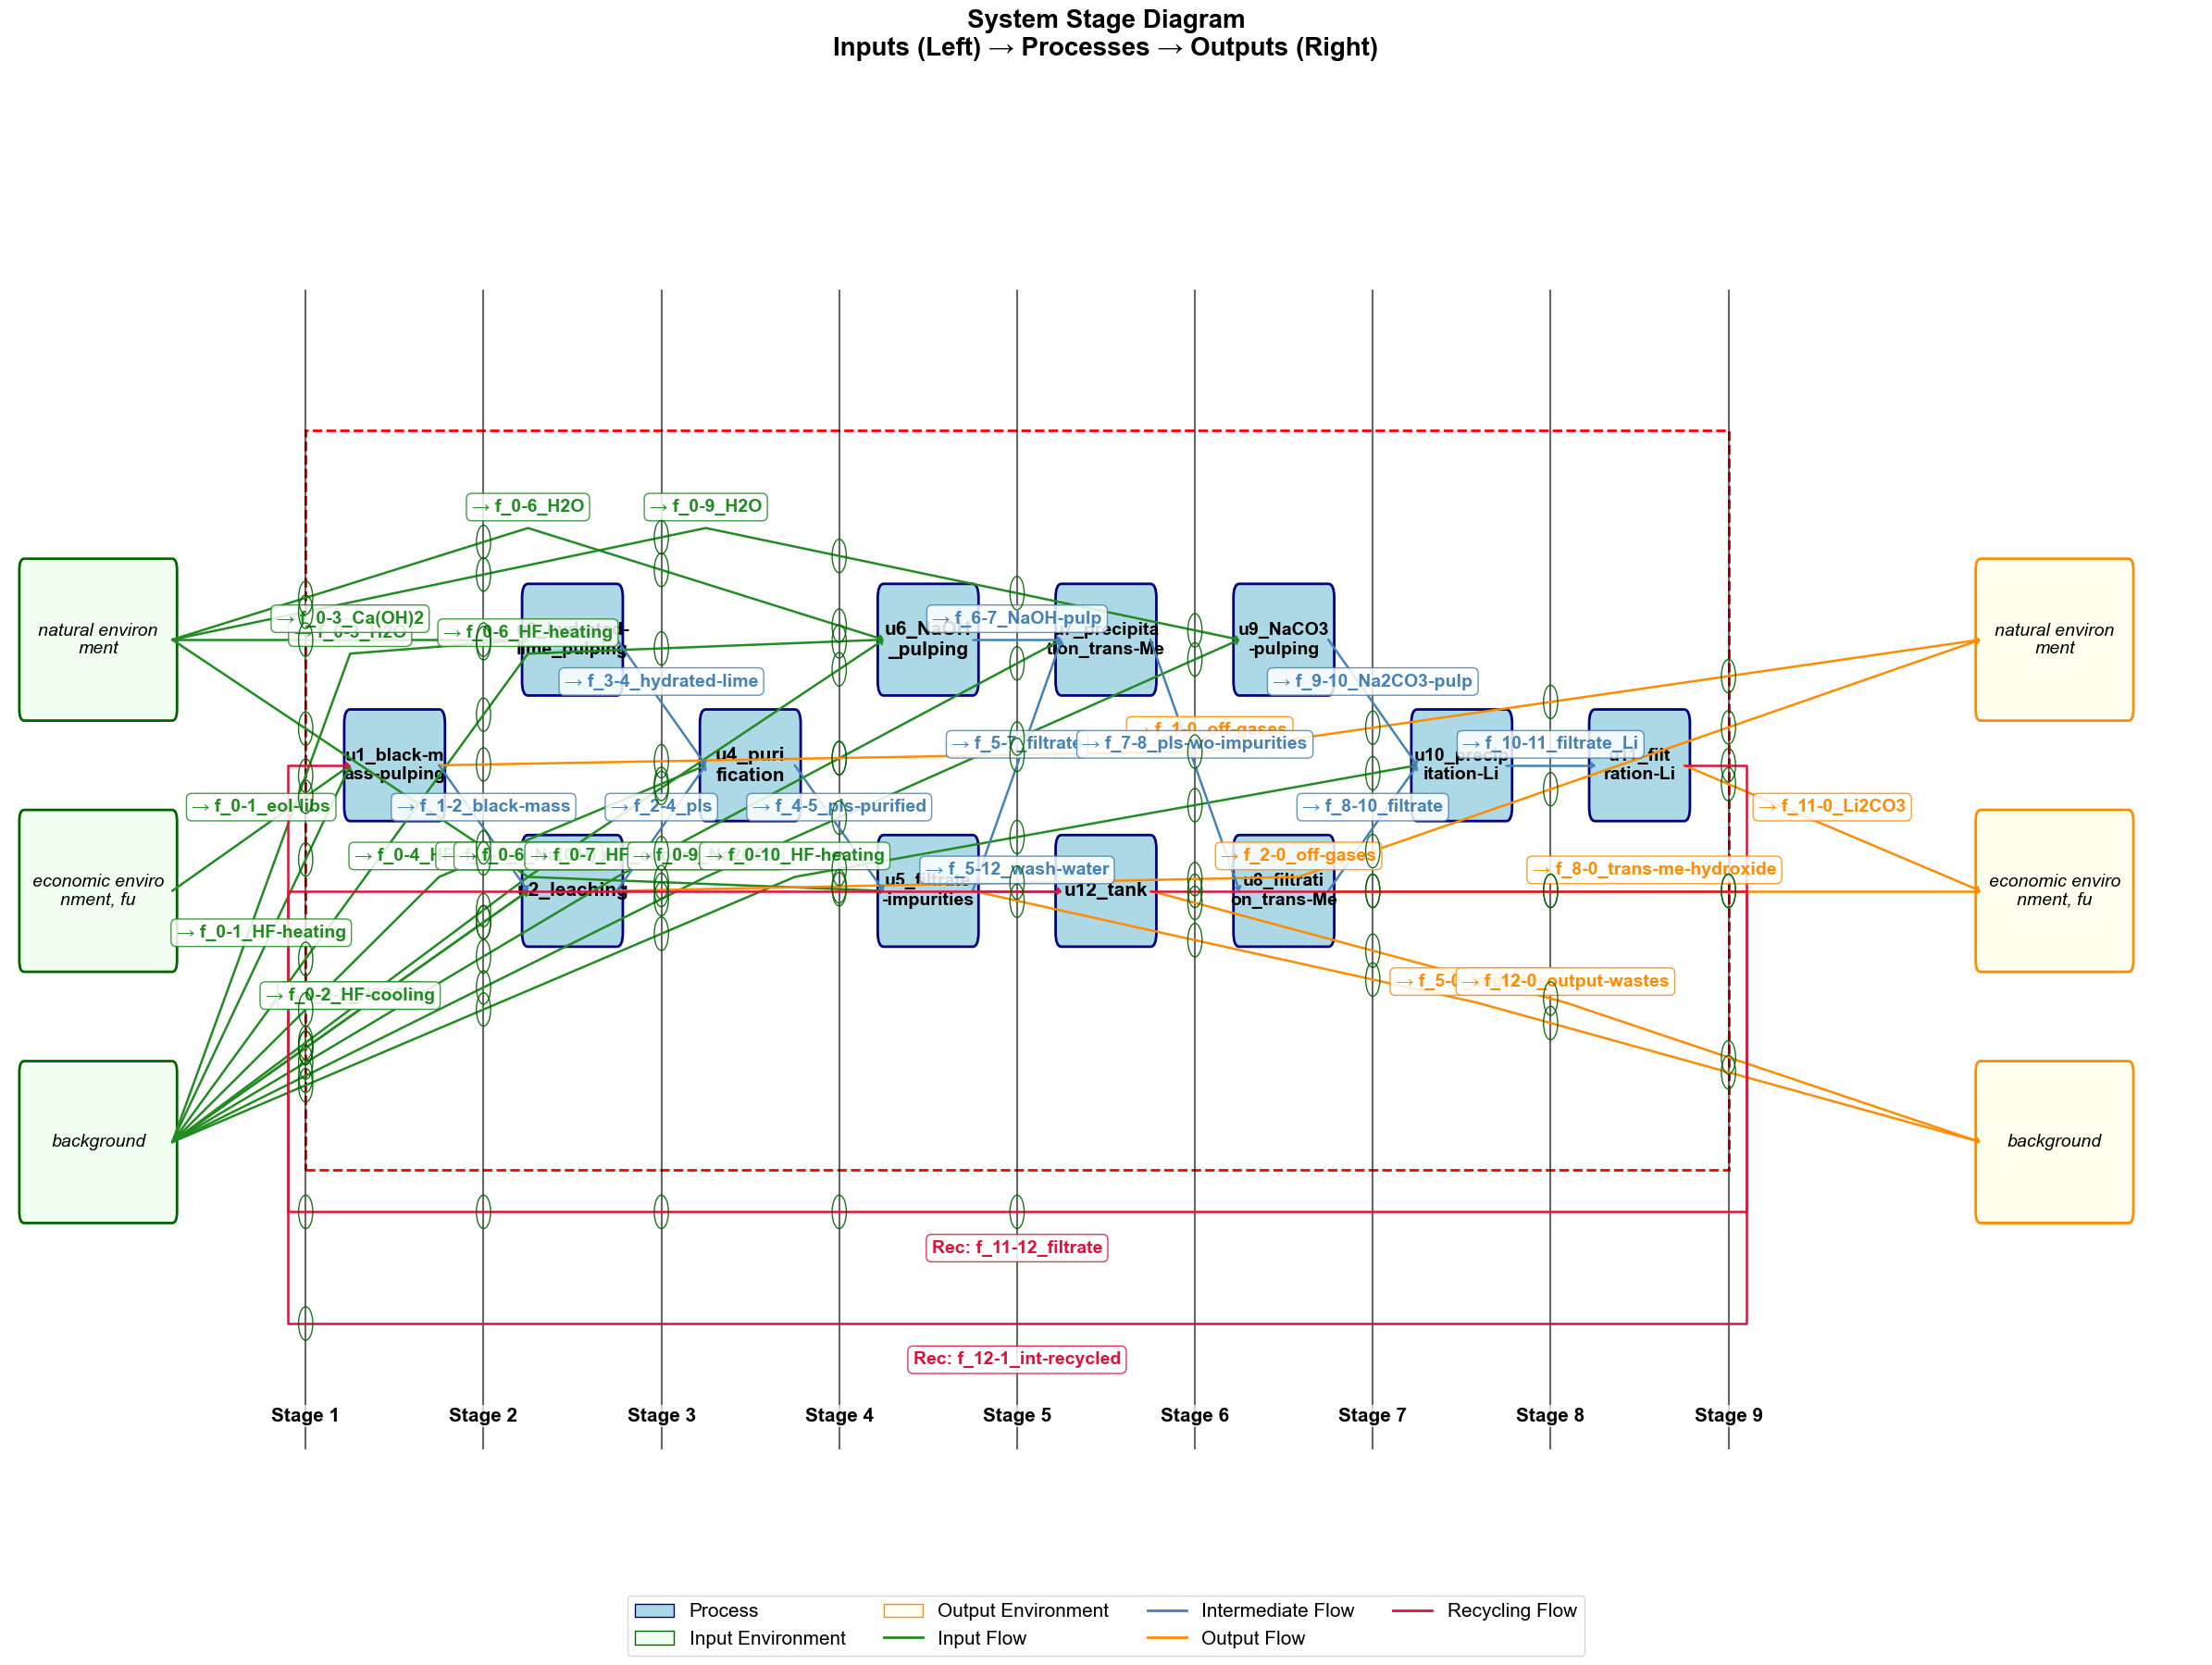

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.path import Path
import matplotlib.patches as patches
import matplotlib.colors as mcolors
from collections import defaultdict
import pandas as pd
import numpy as np

def plot_stage_diagram(
    max_rank_per_process,
    input_env_flows_df,
    output_env_flows_df,
    intermediate_foreground_flows_df,
    recycling_flows_df,
    stage_dfs=None,
    figsize=(20, 14),
    save_svg=True,
    filename="stage_diagram",
    system_boundary_color="red",
    stage_line_color="black",
    process_color="lightblue",
    input_env_color="honeydew",
    output_env_color="ivory",
    flow_colors={
        "input": "forestgreen",
        "intermediate": "steelblue",
        "output": "darkorange",
        "recycling": "crimson",
    },
):
    """
    Plot a stage diagram with processes between stage lines,
    flows with proper offset to avoid overlap, and clear direction indicators.
    """

    # =========================================================================
    # FONT SETTINGS
    # =========================================================================
    apply_style()
    caption_font_size = 15
    title_font_size = 20

    # Box dimensions
    process_width = 1.5
    process_height = 0.6
    env_width = 2.5
    env_height = 1

    # for text limit in the graph
    text_limit = 25

    # Spacing between stages
    stage_spacing = 3.0

    # arrow style
    arrows_style = f"->,head_width=2,head_length=2"
    
    # =========================================================================
    # 1. PREPARE DATA
    # =========================================================================
    max_stage = max(max_rank_per_process.values()) if max_rank_per_process else 1
    all_processes = set(max_rank_per_process.keys())

    # Input/Output environments
    input_envs = set(input_env_flows_df["provider"].dropna().unique()) if not input_env_flows_df.empty else set()
    output_envs = set(output_env_flows_df["consumer"].dropna().unique()) if not output_env_flows_df.empty else set()

    # =========================================================================
    # 2. SETUP FIGURE
    # =========================================================================
    fig, ax = plt.subplots(figsize=figsize)
    
    x_min = -5
    x_max = (max_stage + 1) * stage_spacing + 5
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-12, 12)
    ax.axis("off")

    # =========================================================================
    # 3. POSITION PROCESSES
    # =========================================================================
    rank_groups = defaultdict(list)
    for p in sorted(all_processes):
        r = max_rank_per_process.get(p, 1)
        rank_groups[r].append(p)

    process_pos = {}
    
    for rank in sorted(rank_groups.keys()):
        procs = rank_groups[rank]
        left_stage_x = (rank - 1) * stage_spacing
        right_stage_x = rank * stage_spacing
        x_center = (left_stage_x + right_stage_x) / 2
        
        n_processes = len(procs)
        vertical_spacing = 1.8
        total_height = (n_processes - 1) * vertical_spacing
        start_y = -total_height / 2
        
        for i, proc in enumerate(procs):
            y_center = start_y + i * vertical_spacing
            process_pos[proc] = (x_center, y_center, process_width, process_height)
    
    # Update y-limits
    all_process_y = [y for _, y, _, _ in process_pos.values()]
    y_min = min(all_process_y) - 4
    y_max = max(all_process_y) + 4
    ax.set_ylim(y_min, y_max)

    # =========================================================================
    # 4. POSITION INPUT/OUTPUT NODES
    # =========================================================================
    input_env_pos = {}
    for i, env in enumerate(sorted(input_envs)):
        x = x_min + 1.5
        y = (i - len(input_envs) / 2) * 1.8
        input_env_pos[env] = (x, y, env_width, env_height)

    output_env_pos = {}
    for i, env in enumerate(sorted(output_envs)):
        x = x_max - 2.5
        y = (i - len(output_envs) / 2) * 1.8
        output_env_pos[env] = (x, y, env_width, env_height)

    # =========================================================================
    # 5. DRAW SYSTEM BOUNDARY
    # =========================================================================
    process_x_coords = [x for x, _, _, _ in process_pos.values()]
    process_y_coords = [y for _, y, _, _ in process_pos.values()]
    
    boundary_x_min = min(process_x_coords) - 1.5
    boundary_x_max = max(process_x_coords) + 1.5
    boundary_y_min = min(process_y_coords) - 2
    boundary_y_max = max(process_y_coords) + 1.5

    system_boundary = mpatches.Rectangle(
        (boundary_x_min, boundary_y_min),
        boundary_x_max - boundary_x_min,
        boundary_y_max - boundary_y_min,
        fill=False,
        edgecolor=system_boundary_color,
        linestyle="--",
        linewidth=2,
        label="System Boundary",
    )
    ax.add_patch(system_boundary)

    # =========================================================================
    # 6. DRAW STAGE LINES
    # =========================================================================
    for s in range(1, max_stage + 2):
        stage_x = (s - 1) * stage_spacing
        # Convert data coordinates to axes coordinates for ymin/ymax
        y_lower = boundary_y_min - 2  # Bottom of the line
        y_upper = boundary_y_max + 1  # Top of the line
        ax.axvline(x=stage_x, ymin=(y_lower - ax.get_ylim()[0]) / (ax.get_ylim()[1] - ax.get_ylim()[0]), 
                ymax=(y_upper - ax.get_ylim()[0]) / (ax.get_ylim()[1] - ax.get_ylim()[0]),
                color=stage_line_color, linestyle="-", linewidth=1.5, alpha=0.6, zorder=1)
        ax.text(
            stage_x, boundary_y_min - 1.8, 
            f"Stage {s}", 
            ha="center", 
            fontsize=caption_font_size, 
            color=stage_line_color, 
            fontweight="bold",
            bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=2),
            zorder=2
        )

    # =========================================================================
    # 7. DRAW NODES
    # =========================================================================
    process_boxes = {}
    input_env_boxes = {}
    output_env_boxes = {}

    # Process nodes
    for proc, (x, y, w, h) in process_pos.items():
        rect = mpatches.FancyBboxPatch(
            (x - w / 2, y - h / 2), w, h,
            boxstyle="round,pad=0.1",
            facecolor=process_color,
            edgecolor="navy",
            linewidth=2,
            zorder=10
        )
        ax.add_patch(rect)
        process_boxes[proc] = rect
        
        text_length = len(proc)
        if text_length <= 15:
            text_fontsize = caption_font_size
        elif text_length <= 25:
            text_fontsize = caption_font_size - 1
        elif text_length <= 35:
            text_fontsize = caption_font_size - 2
        else:
            text_fontsize = caption_font_size - 3
        
        # Simple text wrapping
        if text_length > 12:
            split_at = text_length // 2
            label = proc[:split_at] + '\n' + proc[split_at:]
        else:
            label = proc
        
        ax.text(x, y, label, ha="center", va="center", fontsize=text_fontsize, 
                fontweight="bold", linespacing=1.2, zorder=11)

    # Input environment nodes
    for env, (x, y, w, h) in input_env_pos.items():
        rect = mpatches.FancyBboxPatch(
            (x - w / 2, y - h / 2), w, h,
            boxstyle="round,pad=0.08",
            facecolor=input_env_color,
            edgecolor="darkgreen",
            linewidth=2,
            zorder=10
        )
        ax.add_patch(rect)
        input_env_boxes[env] = rect
        
        label = env if len(env) <= 18 else env[:15] + '\n' + env[15:]
        ax.text(x, y, label, ha="center", va="center", fontsize=caption_font_size - 1, 
                style="italic", linespacing=1.1, zorder=11)

    # Output environment nodes
    for env, (x, y, w, h) in output_env_pos.items():
        rect = mpatches.FancyBboxPatch(
            (x - w / 2, y - h / 2), w, h,
            boxstyle="round,pad=0.08",
            facecolor=output_env_color,
            edgecolor="darkorange",
            linewidth=2,
            zorder=10
        )
        ax.add_patch(rect)
        output_env_boxes[env] = rect
        
        label = env if len(env) <= 18 else env[:15] + '\n' + env[15:]
        ax.text(x, y, label, ha="center", va="center", fontsize=caption_font_size - 1, 
                style="italic", linespacing=1.1, zorder=11)

    # =========================================================================
    # 8. HELPER FUNCTIONS
    # =========================================================================
    def get_box_border_point(box, target_x, target_y):
        """Get exact point on box border - simplified to use cardinal directions."""
        bbox = box.get_bbox()
        x0, y0 = bbox.x0, bbox.y0
        x1, y1 = bbox.x1, bbox.y1
        center_x = (x0 + x1) / 2
        center_y = (y0 + y1) / 2
        
        dx = target_x - center_x
        dy = target_y - center_y
        
        # Determine which side to exit from
        if abs(dx) > abs(dy):
            # Exit from left or right side
            if dx > 0:
                return (x1, center_y)  # Right side
            else:
                return (x0, center_y)  # Left side
        else:
            # Exit from top or bottom side
            if dy > 0:
                return (center_x, y1)  # Top side
            else:
                return (center_x, y0)  # Bottom side
            
    def get_node_border_point(node_name, target_x, target_y, node_type=None):
        if node_type == 'input_env' and node_name in input_env_boxes:
            return get_box_border_point(input_env_boxes[node_name], target_x, target_y)
        if node_type == 'output_env' and node_name in output_env_boxes:
            return get_box_border_point(output_env_boxes[node_name], target_x, target_y)
        if node_name in process_boxes:
            return get_box_border_point(process_boxes[node_name], target_x, target_y)
        if node_name in input_env_boxes:
            return get_box_border_point(input_env_boxes[node_name], target_x, target_y)
        if node_name in output_env_boxes:
            return get_box_border_point(output_env_boxes[node_name], target_x, target_y)
        if node_name in process_pos:
            return (process_pos[node_name][0], process_pos[node_name][1])
        elif node_name in input_env_pos:
            return (input_env_pos[node_name][0], input_env_pos[node_name][1])
        elif node_name in output_env_pos:
            return (output_env_pos[node_name][0], output_env_pos[node_name][1])
        return None
    
    def draw_stage_intersection(x, y, stage_num):
        """Draw a green circle at stage line intersection."""
        circle = plt.Circle((x, y), radius=0.12, facecolor='none', #type: ignore
                           edgecolor='darkgreen', linewidth=1, zorder=18, alpha=0.9)
        ax.add_patch(circle)

    # =========================================================================
    # 9. CREATE FLOW STAGES MAPPING
    # =========================================================================
    flow_stages_map = {}

    # For intermediate flows
    for _, row in intermediate_foreground_flows_df.iterrows():
        flow_key = (row["provider_process"], row["consumer_process"], row.get("flow_name", ""))
        provider_rank = max_rank_per_process.get(row["provider_process"], 1)
        consumer_rank = max_rank_per_process.get(row["consumer_process"], 1)
        stages = list(range(provider_rank, consumer_rank + 1))
        flow_stages_map[flow_key] = stages

    # For recycling flows
    for _, row in recycling_flows_df.iterrows():
        flow_key = (row["producer_process"], row["consumer_process"], row.get("flow_name", ""))
        producer_rank = max_rank_per_process.get(row["producer_process"], 1)
        consumer_rank = max_rank_per_process.get(row["consumer_process"], 1)
        start_stage = min(producer_rank, consumer_rank)
        end_stage = max(producer_rank, consumer_rank)
        stages = list(range(start_stage, end_stage + 1))
        flow_stages_map[flow_key] = stages

    # For input flows
    for _, row in input_env_flows_df.iterrows():
        flow_key = (row["provider"], row["consumer_process"], row.get("flow_name", ""))
        consumer_rank = max_rank_per_process.get(row["consumer_process"], 1)
        stages = list(range(1, consumer_rank + 1))
        flow_stages_map[flow_key] = stages

    # For output flows
    for _, row in output_env_flows_df.iterrows():
        flow_key = (row["producer_process"], row["consumer"], row.get("flow_name", ""))
        producer_rank = max_rank_per_process.get(row["producer_process"], 1)
        stages = list(range(producer_rank, max_stage + 1))
        flow_stages_map[flow_key] = stages

    # =========================================================================
    # 10. ASSIGN VERTICAL OFFSETS TO AVOID OVERLAP
    # =========================================================================
    flow_offsets = {}
    
    # Collect all flows grouped by path
    path_groups = defaultdict(list)
    
    for _, row in input_env_flows_df.iterrows():
        from_name = row["provider"]
        to_name = row["consumer_process"]
        from_rank = 0
        to_rank = max_rank_per_process.get(to_name, 1)
        path_key = (min(from_rank, to_rank), max(from_rank, to_rank), 'input')
        path_groups[path_key].append((from_name, to_name, row.get("flow_name", ""), 'input'))
    
    for _, row in output_env_flows_df.iterrows():
        from_name = row["producer_process"]
        to_name = row["consumer"]
        from_rank = max_rank_per_process.get(from_name, 1)
        to_rank = max_stage + 1
        path_key = (min(from_rank, to_rank), max(from_rank, to_rank), 'output')
        path_groups[path_key].append((from_name, to_name, row.get("flow_name", ""), 'output'))
    
    for _, row in intermediate_foreground_flows_df.iterrows():
        from_name = row["provider_process"]
        to_name = row["consumer_process"]
        from_rank = max_rank_per_process.get(from_name, 1)
        to_rank = max_rank_per_process.get(to_name, 1)
        path_key = (min(from_rank, to_rank), max(from_rank, to_rank), 'intermediate')
        path_groups[path_key].append((from_name, to_name, row.get("flow_name", ""), 'intermediate'))
    
    for _, row in recycling_flows_df.iterrows():
        from_name = row["producer_process"]
        to_name = row["consumer_process"]
        from_rank = max_rank_per_process.get(from_name, 1)
        to_rank = max_rank_per_process.get(to_name, 1)
        path_key = (min(from_rank, to_rank), max(from_rank, to_rank), 'recycling')
        path_groups[path_key].append((from_name, to_name, row.get("flow_name", ""), 'recycling'))
    
    # Assign offsets to each flow in each group
    for path_key, flows in path_groups.items():
        num_flows = len(flows)
        for i, (from_name, to_name, flow_name, flow_type) in enumerate(flows):
            # Distribute offsets evenly between -0.6 and 0.6
            if num_flows == 1:
                offset = 0
            else:
                offset = -0.5 + (i / (num_flows - 1)) * 1.0
            flow_offsets[(from_name, to_name, flow_name)] = offset

    # =========================================================================
    # 11. BUILD FLOW STAGE MAPPING FROM stage_dfs
    # =========================================================================
    flow_stage_mapping = {}  # (flow_name, from_process, to_process) -> set of stages
    
    if stage_dfs:
        for stage_num, stage_df in stage_dfs.items():
            if stage_df.empty:
                continue
            for _, row in stage_df.iterrows():
                flow_name = row.get("flow_name")
                from_process = row.get("from_process")
                to_process = row.get("to_process")
                if flow_name:
                    key = (flow_name, from_process, to_process)
                    if key not in flow_stage_mapping:
                        flow_stage_mapping[key] = set()
                    flow_stage_mapping[key].add(stage_num)

    # =========================================================================
    # 12. DRAW ARROW FUNCTION
    # =========================================================================
    # Initialize recycling flow counter for unique Y positions
    recycling_counter = [0]  # Use list for mutable counter in nested function
    
    def draw_stage_markers_for_flow(flow_name, from_process, to_process, waypoints, flow_type):
        """
        Draw green circles at stage lines where this flow belongs,
        based on stage_dfs information and waypoint geometry.
        """
        key = (flow_name, from_process, to_process)
        if key not in flow_stage_mapping:
            return
        
        stages = flow_stage_mapping[key]
        
        for stage in stages:
            stage_x = (stage - 1) * stage_spacing
            
            # Find where this stage line intersects with the flow path
            intersection_y = None
            
            for i in range(len(waypoints) - 1):
                x1, y1 = waypoints[i]
                x2, y2 = waypoints[i + 1]
                
                # Check if stage_x lies between x1 and x2
                if min(x1, x2) <= stage_x <= max(x1, x2):
                    if x2 != x1:
                        # Calculate intersection point
                        t = (stage_x - x1) / (x2 - x1)
                        t = max(0, min(1, t))
                        intersection_y = y1 + t * (y2 - y1)
                    else:
                        # Vertical line - use the midpoint
                        intersection_y = (y1 + y2) / 2
                    break
                # Also check if the point is very close to the stage line
                elif abs(x1 - stage_x) < 0.1:
                    intersection_y = y1
                    break
            
            if intersection_y is not None:
                draw_stage_intersection(stage_x, intersection_y, stage)

    def draw_arrow(from_name, to_name, flow_type, flow_name, to_node_type, from_node_type, flow_stages, vertical_offset):
        """Draw an arrow with proper offset to avoid overlap."""
        
        # Get centers
        from_center = None
        to_center = None
        
        if from_node_type == 'input_env' and from_name in input_env_pos:
            from_center = (input_env_pos[from_name][0], input_env_pos[from_name][1])
        elif from_node_type == 'output_env' and from_name in output_env_pos:
            from_center = (output_env_pos[from_name][0], output_env_pos[from_name][1])
        elif from_name in process_pos:
            from_center = (process_pos[from_name][0], process_pos[from_name][1])
        elif from_name in input_env_pos:
            from_center = (input_env_pos[from_name][0], input_env_pos[from_name][1])
        elif from_name in output_env_pos:
            from_center = (output_env_pos[from_name][0], output_env_pos[from_name][1])
        
        if to_node_type == 'output_env':
            if to_name in output_env_pos:
                to_center = (output_env_pos[to_name][0], output_env_pos[to_name][1])
        elif to_node_type == 'input_env':
            if to_name in input_env_pos:
                to_center = (input_env_pos[to_name][0], input_env_pos[to_name][1])
        else:
            if to_name in process_pos:
                to_center = (process_pos[to_name][0], process_pos[to_name][1])
            elif to_name in input_env_pos:
                to_center = (input_env_pos[to_name][0], input_env_pos[to_name][1])
            elif to_name in output_env_pos:
                to_center = (output_env_pos[to_name][0], output_env_pos[to_name][1])
        
        if not from_center or not to_center:
            return
        
        # Get border points
        from_point = get_node_border_point(from_name, to_center[0], to_center[1], node_type=from_node_type)
        to_point = get_node_border_point(to_name, from_center[0], from_center[1], node_type=to_node_type)
        
        if not from_point or not to_point:
            return
        
        x1, y1 = from_point
        x2, y2 = to_point
        
        # Store original border points for connections
        orig_x1, orig_y1 = x1, y1
        orig_x2, orig_y2 = x2, y2

        color = flow_colors.get(flow_type, "gray")

        def avoid_process_crossing(waypoints, vertical_offset):
            """Add intermediate waypoints to avoid crossing process boxes."""
            if len(waypoints) < 2:
                return waypoints
            
            # Get all process box boundaries
            process_bounds = []
            for proc_name, box in process_boxes.items():
                bbox = box.get_bbox()
                process_bounds.append({
                    'name': proc_name,
                    'x0': bbox.x0, 'x1': bbox.x1,
                    'y0': bbox.y0, 'y1': bbox.y1
                })
            
            # Check each segment for process crossing
            new_waypoints = [waypoints[0]]
            
            for i in range(1, len(waypoints)):
                start_x, start_y = new_waypoints[-1]
                end_x, end_y = waypoints[i]
                
                # Check if this segment crosses any process
                crossed_process = None
                for proc in process_bounds:
                    # Simple line-rectangle intersection check
                    if (max(start_x, end_x) > proc['x0'] and min(start_x, end_x) < proc['x1'] and
                        max(start_y, end_y) > proc['y0'] and min(start_y, end_y) < proc['y1']):
                        crossed_process = proc
                        break
                
                if crossed_process:
                    # Add waypoint above or below the process
                    mid_x = (start_x + end_x) / 2
                    if vertical_offset > 0:
                        mid_y = crossed_process['y1'] + 0.5
                    else:
                        mid_y = crossed_process['y0'] - 0.5
                    
                    new_waypoints.append((mid_x, mid_y))
                    new_waypoints.append((end_x, end_y))
                else:
                    new_waypoints.append((end_x, end_y))
            
            return new_waypoints
        
        # Determine from_process and to_process names for stage mapping
        from_process_for_stage = from_name
        to_process_for_stage = to_name

        # Recycling flows - loop outside boundary following all stages
        if flow_type == 'recycling' and flow_stages:
            # Get process ranks
            from_rank = max_rank_per_process.get(from_name, 1)
            to_rank = max_rank_per_process.get(to_name, 1)
            
            # Get border points
            provider_box = process_boxes.get(from_name)
            consumer_box = process_boxes.get(to_name)
            
            if not provider_box or not consumer_box:
                return
            
            # Right border of provider
            bbox_provider = provider_box.get_bbox()
            start_x = bbox_provider.x1
            start_y = (bbox_provider.y0 + bbox_provider.y1) / 2
            
            # Left border of consumer
            bbox_consumer = consumer_box.get_bbox()
            end_x = bbox_consumer.x0
            end_y = (bbox_consumer.y0 + bbox_consumer.y1) / 2
            
            # Calculate vertical position for recycling flow stacking
            # Each recycling flow gets a unique Y position
            spacing = 0.8
            loop_y = boundary_y_min - 0.3 - (recycling_counter[0] * spacing)
            recycling_counter[0] += 1
            
            # Define waypoints - keep within system boundary for green circles
            exit_x = boundary_x_max + 0.3
            reentry_x = boundary_x_min - 0.3
            
            waypoints = [
                (start_x, start_y),
                (exit_x, start_y),
                (exit_x, loop_y),
                (reentry_x, loop_y),
                (reentry_x, end_y),
                (end_x, end_y)
            ]
            
            # Draw the path
            path_data = [(Path.MOVETO, waypoints[0])]
            for i in range(1, len(waypoints)):
                path_data.append((Path.LINETO, waypoints[i]))
            
            path = Path([p[1] for p in path_data], [p[0] for p in path_data])
            arrow_patch = patches.FancyArrowPatch(
                path=path,
                arrowstyle=arrows_style,
                color=color,
                linewidth=1.8,
                zorder=15
            )
            ax.add_patch(arrow_patch)
            
            # Draw stage markers based on stage_dfs - use waypoints within system boundary
            if stage_dfs and flow_name:
                # Create extended waypoints that stay within boundary for green circles
                within_x_max = boundary_x_max
                within_x_min = boundary_x_min
                
                extended_waypoints = [
                    (start_x, start_y),
                    (within_x_max, start_y),
                    (within_x_max, loop_y),
                    (within_x_min, loop_y),
                    (within_x_min, end_y),
                    (end_x, end_y)
                ]
                draw_stage_markers_for_flow(flow_name, from_process_for_stage, to_process_for_stage, extended_waypoints, flow_type)
            
            # Add label near the bottom loop
            if flow_name:
                label_x = (exit_x + reentry_x) / 2
                label_y = loop_y - 0.2
                ax.text(
                    label_x, label_y,
                    f"Rec: {flow_name[:text_limit]}{'...' if len(flow_name) > text_limit else ''}",
                    ha="center", va="top", fontsize=caption_font_size - 1,
                    color=color, fontweight='bold',
                    bbox=dict(facecolor="white", alpha=0.85, edgecolor=color, pad=2, boxstyle='round,pad=0.3'),
                    zorder=16
                )
            
            return

        # Non-recycling flows - straight with stage crossings
        if flow_stages and len(flow_stages) > 0:
            # Adjust x2 for output flows
            effective_x1 = x1
            effective_x2 = x2
            
            if flow_type == 'output':
                last_stage_x = max_stage * stage_spacing
                if effective_x2 < last_stage_x:
                    effective_x2 = last_stage_x

            # Build waypoints - start and end at original border points
            waypoints = [(orig_x1, orig_y1), (orig_x2, orig_y2)]
            
            # Avoid crossing processes
            waypoints = avoid_process_crossing(waypoints, vertical_offset)
            
            # Draw path
            path_data = [(Path.MOVETO, waypoints[0])]
            for i in range(1, len(waypoints)):
                path_data.append((Path.LINETO, waypoints[i]))
            
            path = Path([p[1] for p in path_data], [p[0] for p in path_data])
            arrow_patch = patches.FancyArrowPatch(
                path=path,
                arrowstyle=arrows_style,
                color=color,
                linewidth=1.8,
                zorder=15
            )
            ax.add_patch(arrow_patch)
            
            # Draw stage markers based on stage_dfs
            if stage_dfs and flow_name:
                draw_stage_markers_for_flow(flow_name, from_process_for_stage, to_process_for_stage, waypoints, flow_type)
            
            # Add label at midpoint
            if flow_name:
                if len(waypoints) > 2:
                    mid_idx = len(waypoints) // 2
                    mid_x, mid_y = waypoints[mid_idx]
                else:
                    mid_x, mid_y = (x1 + x2) / 2, (y1 + y2) / 2
                
                ax.text(
                    mid_x, mid_y + 0.15,
                    f"→ {flow_name[:text_limit]}{'...' if len(flow_name) > text_limit else ''}",
                    ha="center", va="center", fontsize=caption_font_size - 1,
                    color=color, fontweight='bold',
                    bbox=dict(facecolor="white", alpha=0.85, edgecolor=color, pad=2, boxstyle='round,pad=0.3'),
                    zorder=16
                )
        else:
            # For simple arrows
            rad = 0.1 + vertical_offset * 0.15
            ax.annotate(
                "",
                xy=(orig_x2, orig_y2), xytext=(orig_x1, orig_y1),
                arrowprops=dict(
                    arrowstyle=arrows_style,
                    color=color, lw=1.8, connectionstyle=f"arc3,rad={rad}",
                    shrinkA=0, shrinkB=0
                ),
                zorder=13
            )
            
            # Draw stage markers for simple arrows too
            if stage_dfs and flow_name:
                simple_waypoints = [(orig_x1, orig_y1), (orig_x2, orig_y2)]
                draw_stage_markers_for_flow(flow_name, from_process_for_stage, to_process_for_stage, simple_waypoints, flow_type)
            
            if flow_name:
                mid_x, mid_y = (x1 + x2) / 2, (y1 + y2) / 2
                angle = np.arctan2(y2 - y1, x2 - x1)
                perp_angle = angle + np.pi / 2
                mid_x += 0.15 * np.cos(perp_angle)
                mid_y += 0.15 * np.sin(perp_angle)
                
                ax.text(
                    mid_x, mid_y,
                    f"→ {flow_name[:text_limit]}{'...' if len(flow_name) > text_limit else ''}",
                    ha="center", va="center", fontsize=caption_font_size - 1,
                    color=color, fontweight='bold',
                    bbox=dict(facecolor="white", alpha=0.8, edgecolor=color, pad=2, boxstyle='round,pad=0.3'),
                    zorder=14
                )

    # =========================================================================
    # 13. DRAW ALL FLOWS
    # =========================================================================
    # Input flows
    for _, row in input_env_flows_df.iterrows():
        flow_key = (row["provider"], row["consumer_process"], row.get("flow_name", ""))
        offset = flow_offsets.get((row["provider"], row["consumer_process"], row.get("flow_name", "")), 0)
        draw_arrow(
            row["provider"], row["consumer_process"], "input",
            row.get("flow_name", ""),
            to_node_type=None, from_node_type='input_env',
            flow_stages=flow_stages_map.get(flow_key, []),
            vertical_offset=offset
        )

    # Output flows
    for _, row in output_env_flows_df.iterrows():
        flow_key = (row["producer_process"], row["consumer"], row.get("flow_name", ""))
        offset = flow_offsets.get((row["producer_process"], row["consumer"], row.get("flow_name", "")), 0)
        draw_arrow(
            row["producer_process"], row["consumer"], "output",
            row.get("flow_name", ""),
            to_node_type='output_env', from_node_type=None,
            flow_stages=flow_stages_map.get(flow_key, []),
            vertical_offset=offset
        )

    # Intermediate flows
    for _, row in intermediate_foreground_flows_df.iterrows():
        flow_key = (row["provider_process"], row["consumer_process"], row.get("flow_name", ""))
        offset = flow_offsets.get((row["provider_process"], row["consumer_process"], row.get("flow_name", "")), 0)
        draw_arrow(
            row["provider_process"], row["consumer_process"], "intermediate",
            row.get("flow_name", ""),
            to_node_type=None, from_node_type=None,
            flow_stages=flow_stages_map.get(flow_key, []),
            vertical_offset=offset
        )

    # Recycling flows
    for _, row in recycling_flows_df.iterrows():
        flow_key = (row["producer_process"], row["consumer_process"], row.get("flow_name", ""))
        offset = flow_offsets.get((row["producer_process"], row["consumer_process"], row.get("flow_name", "")), 0)
        draw_arrow(
            row["producer_process"], row["consumer_process"], "recycling",
            row.get("flow_name", ""),
            to_node_type=None, from_node_type=None,
            flow_stages=flow_stages_map.get(flow_key, []),
            vertical_offset=offset
        )

    # =========================================================================
    # 14. LEGEND
    # =========================================================================
    legend_elements = [
        mpatches.Patch(facecolor=process_color, edgecolor="navy", label="Process"),
        mpatches.Patch(facecolor=input_env_color, edgecolor="darkgreen", label="Input Environment"),
        mpatches.Patch(facecolor=output_env_color, edgecolor="darkorange", label="Output Environment"),
        Line2D([0], [0], color=flow_colors["input"], lw=2, label="Input Flow"),
        Line2D([0], [0], color=flow_colors["intermediate"], lw=2, label="Intermediate Flow"),
        Line2D([0], [0], color=flow_colors["output"], lw=2, label="Output Flow"),
        Line2D([0], [0], color=flow_colors["recycling"], lw=2, label="Recycling Flow"),
    ]
    ax.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=caption_font_size)
    
    # =========================================================================
    # 15. TITLE
    # =========================================================================
    ax.set_title("System Stage Diagram\nInputs (Left) → Processes → Outputs (Right)", 
                fontsize=title_font_size, fontweight="bold", pad=20)

    plt.tight_layout()

    if save_svg:
        save_figure(fig, filename, RESULTS_DIR, data={
            'input_env_flows': input_env_flows_df,
            'output_env_flows': output_env_flows_df,
            'intermediate_flows': intermediate_foreground_flows_df,
            'recycling_flows': recycling_flows_df,
        })

    plt.show()
    return fig, ax

# Only run if these variables are defined (e.g., in a Jupyter notebook)
if all(var in globals() for var in ['max_rank_per_process', 'input_env_flows_df', 
                                       'output_env_flows_df', 'intermediate_foreground_flows_df',
                                       'recycling_flows_df', 'stage_dfs', 'file_path']):
    fig, ax = plot_stage_diagram(
        max_rank_per_process=max_rank_per_process,
        input_env_flows_df=input_env_flows_df,
        output_env_flows_df=output_env_flows_df,
        intermediate_foreground_flows_df=intermediate_foreground_flows_df,
        recycling_flows_df=recycling_flows_df,
        stage_dfs=stage_dfs,
        figsize=(24, 18),
        filename=f"{file_path}stage_diagram"
    )

## ⚖️ Stages elemental-mass balance

In [15]:
def check_mass_balance(stage_dfs):
    """
    Simple mass balance: element mass per stage using is_chemical_element() for columns.
    """
    # Find element columns
    element_cols = []
    for df in stage_dfs.values():
        if not df.empty:
            element_cols = [col for col in df.columns if is_chemical_element(col)]
            break
    
    # Sum per stage
    rows = []
    for stage in sorted(stage_dfs.keys()):
        df = stage_dfs[stage]
        if df.empty:
            continue
        row = {"stage": stage}
        for _, flow in df.iterrows():
            mass = flow.get("mass-FU_kg-eq", 0)
            if pd.isna(mass) or mass == 0:
                continue
            for e in element_cols:
                if e in flow and pd.notna(flow[e]) and flow[e] != 0:
                    row[e] = row.get(e, 0) + mass * flow[e] / 100
        row["total"] = sum(v for k, v in row.items() if k != "stage")
        rows.append(row)
    
    balance_df = pd.DataFrame(rows).set_index("stage")
    
    print("\n" + "="*60)
    print("ELEMENT MASS PER STAGE (kg-fu)")
    print("="*60)
    print(balance_df.round(6))
    
    return balance_df

balance_df = check_mass_balance(stage_dfs)
balance_df


ELEMENT MASS PER STAGE (kg-fu)
             Al         C        Co        Cu         F         H        Li  \
stage                                                                         
1      0.018740  0.350906  0.078141  0.012950  0.030780  0.817567  0.046044   
2      0.018743  0.350948  0.078147  0.012950  0.031189  0.817624  0.046052   
3      0.018730  0.350933  0.078131  0.012958  0.031189  0.817660  0.046030   
4      0.018719  0.350930  0.078137  0.012952  0.031189  0.817626  0.046041   
5      0.018734  0.350925  0.078155  0.012950  0.031189  0.817646  0.046045   
6      0.018734  0.350916  0.078126  0.012950  0.031189  0.817665  0.046029   
7      0.018734  0.350930  0.078133  0.012950  0.031189  0.817685  0.046034   
8      0.018734  0.350935  0.078133  0.012950  0.031189  0.817692  0.046044   
9      0.018734  0.350941  0.078133  0.012950  0.031189  0.817668  0.046034   

             Mn        Ni          O        P         S        Ca        Na  \
stage              

,Al,C,Co,Cu,F,H,Li,Mn,Ni,O,P,S,Ca,Na,total
stage,,,,,,,,,,,,,,,
1,0.018740,0.350906,0.078141,0.012950,0.030780,0.817567,0.046044,0.072844,0.233479,10.580729,0.00011,2.286566,0.433818,0.559263,15.521936
2,0.018743,0.350948,0.078147,0.012950,0.031189,0.817624,0.046052,0.072849,0.233512,10.581126,0.00011,2.286586,0.433818,0.559287,15.522942
3,0.018730,0.350933,0.078131,0.012958,0.031189,0.817660,0.046030,0.072859,0.233480,10.581243,0.00011,2.286645,0.433757,0.559275,15.523000
4,0.018719,0.350930,0.078137,0.012952,0.031189,0.817626,0.046041,0.072843,0.233467,10.581238,0.00011,2.286670,0.433750,0.559281,15.522953
5,0.018735,0.350925,0.078155,0.012950,0.031189,0.817646,0.046045,0.072826,0.233439,10.581285,0.00011,2.286652,0.433742,0.559271,15.522968
6,0.018735,0.350916,0.078126,0.012950,0.031189,0.817665,0.046029,0.072829,0.233475,10.581269,0.00011,2.286641,0.433742,0.559263,15.522938
7,0.018735,0.350930,0.078133,0.012950,0.031189,0.817685,0.046034,0.072822,0.233460,10.581385,0.00011,2.286658,0.433742,0.559319,15.523152
8,0.018735,0.350935,0.078133,0.012950,0.031189,0.817692,0.046044,0.072822,0.233460,10.581379,0.00011,2.286637,0.433742,0.559360,15.523187
9,0.018735,0.350941,0.078133,0.012950,0.031189,0.817668,0.046034,0.072822,0.233460,10.581390,0.00011,2.286639,0.433742,0.559346,15.523158


# Compute the SEA

Now, we have all the `stage_dfs[i]` for `i` going from `1` to the number of stages of the flowsheet


## for one stage

The `compute_stage_entropy` function updates the `stage_dfs[i]`: 3 columns added. One for the flows Shannon, Rechberger and Relative Statistical Entropy (RSE) information values.

In [16]:
import numpy as np

def compute_stage_entropy(stage_df):
    """
    Compute Shannon, Rechberger, and Relative entropy for each flow in a stage.
    Add these values for each flow of a stage in the stage_dfs dataframe.
    """
    df = stage_df.copy()

    # Identify element columns: all columns after "mass-FU_kg-eq"
    if "mass-FU_kg-eq" not in df.columns:
        raise ValueError("Stage DataFrame must have 'mass-FU_kg-eq' column")
    mass_idx = df.columns.get_loc("mass-FU_kg-eq")
    element_cols = [col for col in df.columns if is_chemical_element(col)]
    
    # Total mass of the stage
    M = df["mass-FU_kg-eq"].sum()

    # Number of elements considered (for relative entropy)
    n_R = len(element_cols)

    # Prepare accumulators
    shannon_vals = []
    rechberger_vals = []
    relative_vals = []

    for _, row in df.iterrows():
        m_j = row["mass-FU_kg-eq"]

        # Initialize entropies for this flow
        H_shannon = 0.0
        H_rechberger = 0.0
        H_relative = 0.0

        for col in element_cols:
            c = row[col]
            if pd.isna(c) or c <= 0:
                continue

            p = c / 100.0  # convert to fraction

            # Shannon
            H_shannon += - p * np.log2(p)

            # Rechberger
            H_rechberger += - (m_j / M) * p * np.log2(p)

            # Relative
            H_relative += - (m_j / M) * p * (np.log(p) / np.log(n_R))  # log base n_R

        shannon_vals.append(H_shannon)
        rechberger_vals.append(H_rechberger)
        relative_vals.append(H_relative)

    # Add new columns
    df["Shannon entropy per flow"] = shannon_vals
    df["Rechberger entropy per flow"] = rechberger_vals
    df["Relative entropy per flow"] = relative_vals

    return df

## for elements

In [54]:
def get_unique_elements(stage_dfs):
    # Exclude non-element columns
    exclude_columns = ['flow_name', 'flow_type', 'from_process', 'to_process', 'mass-FU_kg-eq']
    elements = set()

    for stage, df in stage_dfs.items():
        for col in df.columns:
            if col not in exclude_columns:
                elements.add(col)

    return sorted(list(elements))
    
def group_elements_of_interest(stage_dfs, elements_of_interest):
    """
    Parameters:
    - Require the stages analysis to be done.
    - Require a list of elements of interest.
    
    Actions:
    - Modify stage_dfs to focus only on the list of elements for which we want to measure the contribution to the Statistical Entropies value.
    - A rest column replaces the sum of all the other elements present in the flowsheet.

    Return:
    - a modified restricted stage_dfs dataframe, with the 'elements_of_interest' and the rest fraction.
    """
    modified_stage_dfs = {}

    for stage, df in stage_dfs.items():
        df = df.copy()
        # Identify element columns: all columns after "mass-FU_kg-eq"
        if "mass-FU_kg-eq" not in df.columns:
            raise ValueError("Stage DataFrame must have 'mass-FU_kg-eq' column")
        mass_idx = df.columns.get_loc("mass-FU_kg-eq")
        element_cols = [col for col in df.columns if is_chemical_element(col)]

        # Create a new column for the rest
        rest_col = "Rest"
        df[rest_col] = 100  # Initialize to 100%

        # Subtract the elements of interest from the rest
        for element in elements_of_interest:
            if element in element_cols:
                df[rest_col] -= df[element].fillna(0)

        # Create a new DataFrame with only the elements of interest and the rest
        new_element_cols = elements_of_interest + [rest_col]
        new_element_cols = [col for col in new_element_cols if col in df.columns]

        # Keep only the relevant columns
        relevant_cols = [col for col in df.columns if col not in element_cols or col in new_element_cols]
        modified_df = df[relevant_cols]

        modified_stage_dfs[stage] = modified_df

    return modified_stage_dfs

def compute_element_entropy_across_stages(stage_dfs):
    """
    Parameters:
    - Require the stages analysis to be done.

    Actions:
    - Compute the statistical entropy per element across all stages.

    Return:
    - A dataframe with all the flowsheet's elements (rows) and their corresponding SE and RSE (2 columns) for each stage.
    """
    element_entropy = {stage: {} for stage in stage_dfs}

    for stage, df in stage_dfs.items():
        # Identify element columns: all columns after "mass-FU_kg-eq"
        if "mass-FU_kg-eq" not in df.columns:
            raise ValueError("Stage DataFrame must have 'mass-FU_kg-eq' column")
        mass_idx = df.columns.get_loc("mass-FU_kg-eq")
        element_cols = [col for col in df.columns if is_chemical_element(col)]
        M = df["mass-FU_kg-eq"].sum() # sum of all stage mass flow
        n_R = len(element_cols) # number of elements for normalisation (get the RSE)

        for col in element_cols:
            H_rechberger = 0.0
            H_relative = 0.0

            for _, row in df.iterrows():
                c = row[col]
                m_j = row["mass-FU_kg-eq"]
                if pd.isna(c) or c <= 0:
                    continue
                p = c / 100.0
                H_rechberger += -(m_j / M) * p * np.log2(p)
                H_relative += -(m_j / M) * p * (np.log(p) / np.log(n_R))

            element_entropy[stage][col] = {
                "Rechberger": H_rechberger,
                "Relative": H_relative
            }

    # Convert to DataFrames
    element_entropy_dfs = {}
    for stage, elements in element_entropy.items():
        rows = []
        for col, values in elements.items():
            row = {
                "Element": col,
                "Rechberger": values["Rechberger"],
                "Relative": values["Relative"]
            }
            rows.append(row)
        element_entropy_dfs[stage] = pd.DataFrame(rows).set_index("Element")

    return element_entropy_dfs

def get_element_contributions_per_flow(stage_df, flow_name):
    """
    Parameters:
    - Require a stage dataframe, and the name of one of its flows to analyse. The stage dataframe may be modified by the 'group_elements_of_interest' function.

    Actions:
    - Compute the SE and the RSE value (normalised contribution) attributed to each element that constitutes this flow.

    Return:
    - A pandas DataFrame with element names, Rechberger (SE) contributions, and Relative (RSE) contributions
    """
    
    df = stage_df.copy()
    
    # Identify element columns: all columns after "mass-FU_kg-eq"
    if "mass-FU_kg-eq" not in df.columns:
        raise ValueError("Stage DataFrame must have 'mass-FU_kg-eq' column")
    
    # Get element columns
    all_cols = df.columns.tolist()
    element_cols = [col for col in all_cols if is_chemical_element(col)]
    
    if not element_cols:
        raise ValueError("No element columns found in the dataframe")
    
    # Filter for the specific flow
    flow_matches = df[df["flow_name"] == flow_name]
    if flow_matches.empty:
        raise ValueError(f"Flow '{flow_name}' not found in the dataframe")
    
    flow_data = flow_matches.iloc[0]

    # Calculate total entropy for the flow
    M = df["mass-FU_kg-eq"].sum() 
    m_j = flow_data["mass-FU_kg-eq"]
    n_R = len(element_cols)

    total_rechberger = 0.0
    total_relative = 0.0

    results = []

    for col in element_cols:
        c = flow_data[col]
        if pd.isna(c) or c <= 0:
            results.append({
                'element': col,
                'rechberger_contribution': 0,
                'relative_contribution': 0,
                'rechberger_normalized': 0,
                'relative_normalized': 0
            })
            continue
        
        p = c / 100.0  # Convert percentage to fraction
        rechberger_contribution = -(m_j / M) * p * np.log2(p) if p > 0 else 0
        relative_contribution = -(m_j / M) * p * (np.log(p) / np.log(n_R)) if p > 0 and n_R > 1 else 0

        total_rechberger += rechberger_contribution
        total_relative += relative_contribution

        results.append({
            'element': col,
            'rechberger_contribution': rechberger_contribution,
            'relative_contribution': relative_contribution,
            'rechberger_normalized': 0,  # Will update after total is known
            'relative_normalized': 0      # Will update after total is known
        })

    # Normalize contributions and update results
    for result in results:
        if total_rechberger != 0:
            result['rechberger_normalized'] = result['rechberger_contribution'] / total_rechberger
        if total_relative != 0:
            result['relative_normalized'] = result['relative_contribution'] / total_relative

    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    # Add flow name and mass info as attributes
    results_df.attrs['flow_name'] = flow_name
    results_df.attrs['total_mass'] = M
    results_df.attrs['flow_mass'] = m_j
    
    return results_df

def plot_element_contributions_per_flow(stage_df, flow_name):
    """
    Parameters:
    - Require a stage dataframe, and the name of one of its flows to analyse. The stage dataframe may be modified by the 'group_elements_of_interest' function.

    Actions:
    - Compute the SE and the RSE value (normalised contribution) attributed to each element that constitutes this flow.

    Return:
    - A bar plot: one bar per element and their SE and RSE value along the y-axis.
    """
    
    df = stage_df.copy()
    
    # Identify element columns: all columns after "mass-FU_kg-eq"
    if "mass-FU_kg-eq" not in df.columns:
        raise ValueError("Stage DataFrame must have 'mass-FU_kg-eq' column")
    mass_idx = df.columns.get_loc("mass-FU_kg-eq")
    element_cols = [col for col in df.columns if is_chemical_element(col)]

    # Filter for the specific flow
    flow_data = df[df["flow_name"] == flow_name].iloc[0]

    # Calculate total entropy for the flow
    M = df["mass-FU_kg-eq"].sum() 
    m_j = flow_data["mass-FU_kg-eq"]
    n_R = len(element_cols)

    total_rechberger = 0.0
    total_relative = 0.0

    contributions_rechberger = []
    contributions_relative = []

    for col in element_cols:
        c = flow_data[col]
        if pd.isna(c) or c <= 0:
            contributions_rechberger.append(0)
            contributions_relative.append(0)
            continue
        p = c / 100.0
        rechberger_contribution = -(m_j / M) * p * np.log2(p)
        relative_contribution = -(m_j / M) * p * (np.log(p) / np.log(n_R))

        total_rechberger += rechberger_contribution
        total_relative += relative_contribution

        contributions_rechberger.append(rechberger_contribution)
        contributions_relative.append(relative_contribution)

    # Normalize contributions
    normalized_rechberger = [contribution / total_rechberger if total_rechberger != 0 else 0 for contribution in contributions_rechberger]
    normalized_relative = [contribution / total_relative if total_relative != 0 else 0 for contribution in contributions_relative]

    # Plot contributions
    x = np.arange(len(element_cols))
    width = 0.35

    fig, ax = plt.subplots(figsize=(14, 8))
    rects2 = ax.bar(x, normalized_rechberger, width, label='Rechberger')
    rects3 = ax.bar(x + width, normalized_relative, width, label='Relative')

    ax.set_ylabel('Normalized Contribution to Entropy')
    ax.set_title(f'Normalized Element Contributions to Entropy for Flow: {flow_name}')
    ax.set_xticks(x + width / 2)
    ax.set_xticklabels(element_cols, rotation=90)
    ax.legend()

    fig.tight_layout()
    
    save_figure(fig, f'element_contributions_per_flow_{flow_name}', RESULTS_DIR,
                data=pd.DataFrame({
                    'element': element_cols,
                    'rechberger_normalized': normalized_rechberger,
                    'relative_normalized': normalized_relative,
                }))
   
    plt.show()  # Display the plot interactively
    # plt.close(fig)  # Close the figure after showing it
    
def plot_an_element_contributions_for_stage(stage_df, element):
    """
    Parameters:
    - Require a stage dataframe, and the knowledge of a chemical element to analyse.

    Actions:
    - Compute the SE and RSE value (normalised contribution) of the element in each flow of the stage.

    Return:
    - Plot the normalised contribution of ONE specific element to the entropy of all flows in ONE stage.
    """
    df = stage_df.copy()
    # Identify element columns: all columns after "mass-FU_kg-eq"
    if "mass-FU_kg-eq" not in df.columns:
        raise ValueError("Stage DataFrame must have 'mass-FU_kg-eq' column")
    mass_idx = df.columns.get_loc("mass-FU_kg-eq")
    element_cols = [col for col in df.columns if is_chemical_element(col)]

    if element not in element_cols:
        print(f"Element '{element}' not found in the stage data. Available elements: {element_cols}")
        return

    M = df["mass-FU_kg-eq"].sum() # total mass of the stage
    n_R = len(element_cols)

    contributions_rechberger = []
    contributions_relative = []
    flow_names = []
    total_rechberger_entropies = []
    total_relative_entropies = []

    for _, row in df.iterrows():
        flow_name = row["flow_name"] 
        flow_names.append(flow_name)

        c = row[element]
        m_j = row["mass-FU_kg-eq"]

        total_rechberger = 0.0 
        total_relative = 0.0

        for col in element_cols:
            c_total = row[col]
            if pd.isna(c_total) or c_total <= 0:
                continue
            p_total = c_total / 100.0
            total_rechberger += -(m_j / M) * p_total * np.log2(p_total)
            total_relative += -(m_j / M) * p_total * (np.log(p_total) / np.log(n_R))

        total_rechberger_entropies.append(total_rechberger)
        total_relative_entropies.append(total_relative)

        if pd.isna(c) or c <= 0:
            contributions_rechberger.append(0)
            contributions_relative.append(0)
            continue

        p = c / 100.0
        rechberger_contribution = -(m_j / M) * p * np.log2(p)
        relative_contribution = -(m_j / M) * p * (np.log(p) / np.log(n_R))

        # Normalise contributions, i.e., divide the element's contribution by the total entropy of the flow.
        normalized_rechberger = rechberger_contribution / total_rechberger if total_rechberger != 0 else 0 # This gives the fraction (or percentage) of the total SE that is due to an element
        normalized_relative = relative_contribution / total_relative if total_relative != 0 else 0 # This gives the fraction (or percentage) of the total RSE that is due to an element

        # Stores the normalized contributions for later plotting.
        contributions_rechberger.append(normalized_rechberger)
        contributions_relative.append(normalized_relative)

    x = np.arange(len(flow_names))
    width = 0.35

    fig, ax = plt.subplots(figsize=(14, 8))
    rects2 = ax.bar(x, contributions_rechberger, width, label='Rechberger')
    rects3 = ax.bar(x + width, contributions_relative, width, label='Relative')

    ax.set_ylabel('Normalized Contribution to Entropy')
    ax.set_title(f'Normalized Contribution of {element} to Entropy for All Flows in Stage')
    ax.set_xticks(x + width / 2)
    ax.set_xticklabels(flow_names, rotation=90)
    ax.legend()

    fig.tight_layout()
    save_figure(fig, f'element_contribution_plot_{element}', RESULTS_DIR,
                data=pd.DataFrame({
                    'flow_name': flow_names,
                    'rechberger_normalized': contributions_rechberger,
                    'relative_normalized': contributions_relative,
                }))
    plt.show()

def plot_elements_contributions_for_stage(stage_df, elements, min_contribution=0.01):
    """
    Parameters:
    - stage_df: DataFrame containing the stage data.
    - elements: List of chemical elements to analyze.
    - min_contribution: Minimum contribution (as a fraction) to display the percentage on the bar.

    Actions:
    - Compute the RSE value (normalized contribution) of each element in each flow of the stage.
    - Plot the normalized contribution of the specified elements to the entropy of all flows in the stage.

    Return:
    - Plot with one stacked bar per flow, showing the percentage of each element's contribution.
    """
    df = stage_df.copy()
    # Identify element columns: all columns after "mass-FU_kg-eq"
    if "mass-FU_kg-eq" not in df.columns:
        raise ValueError("Stage DataFrame must have 'mass-FU_kg-eq' column")
    mass_idx = df.columns.get_loc("mass-FU_kg-eq")
    element_cols = [col for col in df.columns if is_chemical_element(col)]

    # Check if all elements are in the dataframe
    missing_elements = [elem for elem in elements if elem not in element_cols]
    if missing_elements:
        print(f"Elements {missing_elements} not found in the stage data. Available elements: {element_cols}")
        return

    M = df["mass-FU_kg-eq"].sum()  # total mass of the stage
    n_R = len(element_cols)

    # Initialize dictionaries to store contributions for each element
    contributions_relative = {elem: [] for elem in elements}
    flow_names = []

    for _, row in df.iterrows():
        flow_name = row["flow_name"]
        flow_names.append(flow_name)

        m_j = row["mass-FU_kg-eq"]

        # Calculate total relative entropy for the flow
        total_relative = 0.0

        for col in element_cols:
            c_total = row[col]
            if pd.isna(c_total) or c_total <= 0:
                continue
            p_total = c_total / 100.0
            total_relative += -(m_j / M) * p_total * (np.log(p_total) / np.log(n_R))

        # Calculate contributions for each element
        for elem in elements:
            c = row[elem]
            if pd.isna(c) or c <= 0:
                contributions_relative[elem].append(0)
                continue

            p = c / 100.0
            relative_contribution = -(m_j / M) * p * (np.log(p) / np.log(n_R))

            # Normalize contributions
            normalized_relative = relative_contribution / total_relative if total_relative != 0 else 0
            contributions_relative[elem].append(normalized_relative)

    # Plotting
    x = np.arange(len(flow_names))
    width = 0.8  # Single bar per flow

    fig, ax = plt.subplots(figsize=(14, 8))

    # Initialize bottom for stacking
    bottom = np.zeros(len(flow_names))

    # Plot each element's contributions as a stacked bar
    for elem in elements:
        bars = ax.bar(x, contributions_relative[elem], width, bottom=bottom, label=elem)
        bottom += contributions_relative[elem]

        # Add percentage labels if contribution is above the threshold
        for i, contribution in enumerate(contributions_relative[elem]):
            if contribution > min_contribution:
                ax.text(x[i], bottom[i] - contribution / 2, f"{contribution:.1%}",
                        ha='center', va='center', color='black', fontsize=8)

    ax.set_ylabel('Normalized Contribution to Relative Entropy')
    ax.set_title(f'Normalized Contribution of Elements to Relative Entropy for All Flows in Stage')
    ax.set_xticks(x)
    ax.set_xticklabels(flow_names, rotation=90)
    ax.set_ylim(0, 1.1)  # Set y-axis scale from 0 to 1.1
    ax.legend()

    fig.tight_layout()
    save_figure(fig, f'element_contribution_plot_{"_".join(elements)}', RESULTS_DIR,
                data=pd.DataFrame({'flow_name': flow_names, **contributions_relative}))
    plt.show()

def plot_stacked_elements_rse_contributions_for_stage(stage_df, stage_key=None):
    """
    Parameters:
    - Require the choice of one stage to analyse, ideally a stage with a high relative statistical entropy value.

    Return:
    - Plot the stacked RSE contribution of all the flowsheet elements to the entropy of all flows in ONE stage.
    - Each element is represented by a different colour within each bar.
    """
    df = stage_df.copy()
    # Identify element columns: all columns after "mass-FU_kg-eq"
    if "mass-FU_kg-eq" not in df.columns:
        raise ValueError("Stage DataFrame must have 'mass-FU_kg-eq' column")
    mass_idx = df.columns.get_loc("mass-FU_kg-eq")
    element_cols = [col for col in df.columns if is_chemical_element(col)]
    
    M = df["mass-FU_kg-eq"].sum()
    n_R = len(element_cols)
    flow_names = df["flow_name"].tolist()

    # Consistent color per element (see figure_style.py)
    colors = [get_element_color(element) for element in element_cols]

    # Prepare data for plotting
    contributions = {element: [] for element in element_cols}
    total_rse_values = []

    for _, row in df.iterrows():
        m_j = row["mass-FU_kg-eq"]
        total_relative = 0.0

        for col in element_cols:
            c = row[col]
            if pd.isna(c) or c <= 0:
                continue
            p = c / 100.0
            total_relative += -(m_j / M) * p * (np.log(p) / np.log(n_R))

        total_rse_values.append(total_relative)

        for col in element_cols:
            c = row[col]
            if pd.isna(c) or c <= 0:
                contributions[col].append(0)
                continue
            p = c / 100.0
            relative_contribution = -(m_j / M) * p * (np.log(p) / np.log(n_R))
            contributions[col].append(relative_contribution)

    # Convert contributions to a numpy array for easier manipulation
    contributions_array = np.array([contributions[col] for col in element_cols])

    # Plot contributions as a stacked bar plot
    fig, ax = plt.subplots(figsize=(14, 14))
    x = np.arange(len(flow_names))
    ax.set_ylabel('RSE Contribution')
    ax.tick_params(axis='both', which='major')

    bottom = np.zeros(len(flow_names))
    for i, element in enumerate(element_cols):
        ax.bar(x, contributions_array[i], bottom=bottom, label=element, color=colors[i])
        bottom += contributions_array[i]

    ax.set_ylabel('RSE Contribution')
    # Set the title after ax is created
    if stage_key is not None:
        ax.set_title(f'Stacked RSE Contribution of All Elements for All Flows in Stage {stage_key}')
    else:
        ax.set_title('Stacked RSE Contribution of All Elements for All Flows in Stage')

    ax.set_xticks(x)
    ax.set_xticklabels(flow_names, rotation=90)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    fig.tight_layout()
    save_figure(fig, f'stacked_elements_rse_contributions_stage_{stage_key}', RESULTS_DIR,
                data=pd.DataFrame({'flow_name': flow_names, **contributions}))
    plt.show()

# Element colors and get_element_color now come from figure_style.py
def plot_element_entropy_evolution(element_entropy_dfs, elements, plot_total=False, file_path=''):
    """
    Parameters:
    - element_entropy_dfs: dataframe computed by 'compute_element_entropy_across_stages(stage_dfs)'
    - elements: list of element(s) to analyse its RSE evolution
    - plot_total: bool, if True, plots total RSE (sum of all elements) on same y-axis
    - file_path: path to save the figure

    Return:
    - A plot of the evolution of elements' Relative Statistical entropy (RSE) across stages.
    """
    # Convert single element to a list
    if isinstance(elements, str):
        elements = [elements]

    stages = sorted(element_entropy_dfs.keys())

    fig, ax = plt.subplots(figsize=(10, 6))

    # Plot RSE for each element with consistent colors
    element_series = {}
    for element in elements:
        relative_entropy = []

        for stage in stages:
            try:
                relative_entropy.append(element_entropy_dfs[stage].loc[element, "Relative"])
            except KeyError:
                print(f"Element '{element}' not found in stage {stage}. Available elements: {element_entropy_dfs[stage].index.tolist()}")
                relative_entropy.append(np.nan)

        # Get consistent color
        color = get_element_color(element)
        ax.plot(stages, relative_entropy, marker='s', color=color, linewidth=2, 
                markersize=8, label=f'{element} RSE')
        element_series[f'{element} RSE'] = relative_entropy

    # Plot total RSE (always black)
    if plot_total:
        total_rse = []
        for stage in stages:
            total_rse.append(element_entropy_dfs[stage]["Relative"].sum())
        
        ax.plot(stages, total_rse, marker='o', color='black', linestyle='--', 
                linewidth=2.5, markersize=8, label='Total RSE (all elements)', zorder=10)
        element_series['Total RSE (all elements)'] = total_rse

    # Add title and labels
    plt.title('Evolution of Relative Statistical Entropy Across Stages', fontweight='bold')
    ax.set_xlabel('Stage')
    ax.set_ylabel('Relative Statistical Entropy')
    ax.legend(loc='upper left', framealpha=0.9)
    ax.grid(True, alpha=0.3, linestyle='--')

    plt.tight_layout()
    
    save_figure(fig, f'element_entropy_evolution_{"_".join(elements)}', RESULTS_DIR,
                data=pd.DataFrame({'stage': stages, **element_series}))
    
    plt.show()

## general

In [18]:
def compute_all_stages_entropy(stage_dfs):
    """
    Compute Shannon, Rechberger, and Relative entropy for each flow in all stages.
    Uses the compute_stage_entropy function for each stage.

    Parameters:
    - stage_dfs: Dictionary of DataFrames, where each key is a stage name and the value is the stage DataFrame.

    Returns:
    - Dictionary of DataFrames with added entropy columns for each stage.
    """
    stage_dfs_with_entropies = {}

    for stage, df in stage_dfs.items():
        # Compute entropy for this stage
        general_df_with_entropies = compute_stage_entropy(df)
        stage_dfs_with_entropies[stage] = general_df_with_entropies

    return stage_dfs_with_entropies 

def summarize_entropy(all_stages_with_entropies):
    """
    Summarize entropy results across all stages.
    
    Parameters:
    - all_stages_with_entropies: Dictionary of {stage_name: DataFrame} with computed entropy columns
    
    Returns:
    - DataFrame summarizing entropy metrics per stage
    """
    summary = {}
    
    # Fixed: using the parameter name consistently
    for stage, df in all_stages_with_entropies.items():
        total_rechberger = df["Rechberger entropy per flow"].sum()
        total_relative = df["Relative entropy per flow"].sum()
        
        summary[stage] = {
            "Rechberger entropy [bits]": total_rechberger,
            "Relative entropy [normalized amount]": total_relative,
        }
    
    return pd.DataFrame(summary).T  # Transpose for stages as rows

def plot_entropy(summary_df):
    """
    Plot SE and RSE across stages with dual y-axes.
    
    Parameters:
    - summary_df: The entropy summarized results from summarize_entropy()
    
    Returns:
    - The evolution of SE and RSE across the flowsheet's stages
    """
    # summary_df already has stages as rows, metrics as columns
    plot_df = summary_df.copy()
    
    # Sort by stage index (convert to int if needed)
    plot_df = plot_df.sort_index()
    
    # Replace infinities and NaNs
    plot_df = plot_df.replace([np.inf, -np.inf], np.nan).fillna(0)

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Get x-axis values (stage indices)
    stages = plot_df.index.tolist()
    
    # Plot SE on the left y-axis
    color_se = SE_COLOR
    ax1.set_xlabel("Stage")
    ax1.set_ylabel("SE [bits]", color=color_se)
    ax1.plot(
        stages,
        plot_df["Rechberger entropy [bits]"],
        marker="o",
        color=color_se,
        label="SE [bits]"
    )
    ax1.tick_params(axis='y', labelcolor=color_se)
    ax1.grid(True)
    
    # Set x-ticks to show all stages
    ax1.set_xticks(stages)

    # Create a second y-axis for RSE
    ax2 = ax1.twinx()
    color_rse = RSE_COLOR
    ax2.set_ylabel("RSE [normalised amount]", color=color_rse)
    ax2.plot(
        stages,
        plot_df["Relative entropy [normalized amount]"],
        marker="s",
        color=color_rse,
        label="RSE [normalised amount]"
    )
    ax2.tick_params(axis='y', labelcolor=color_rse)

    # Add title and legend
    plt.title("Entropy Evolution Across Stages")
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

    plt.tight_layout()
    save_figure(fig, 'entropy_evolution_across_stages', RESULTS_DIR, data=plot_df)
    plt.show()

## 📈 Main Execution and first results

   Rechberger entropy [bits]  Relative entropy [normalized amount]
1                   1.042266                              0.266776
2                   1.079817                              0.276388
3                   1.220731                              0.312456
4                   1.310189                              0.335353
5                   1.307748                              0.334729
6                   1.370021                              0.350668
7                   1.348062                              0.345047
8                   1.362191                              0.348664
9                   1.349742                              0.345477


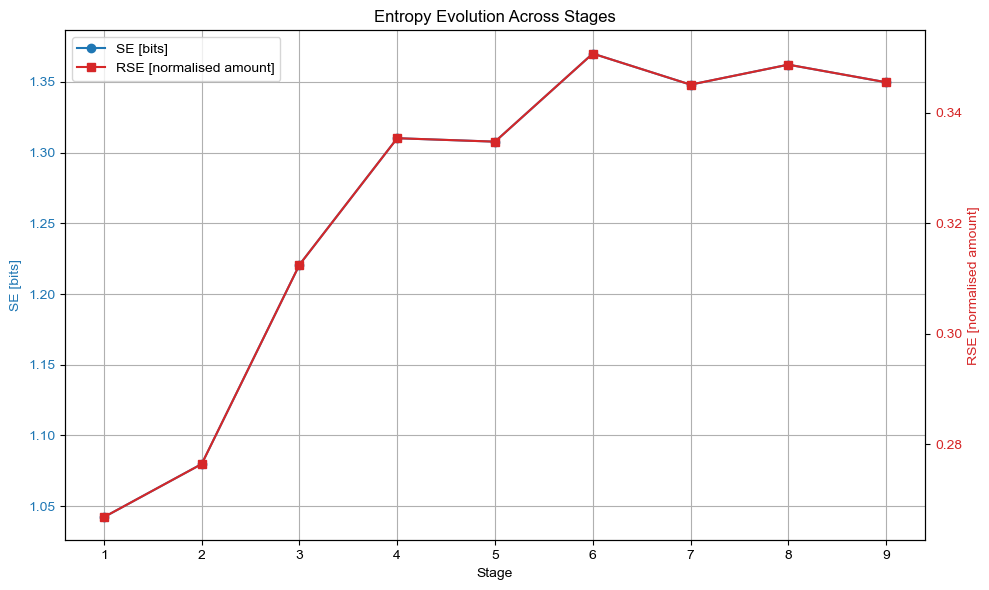

In [27]:
# Step 1: Compute entropy for all stages
all_stage_s_dfs = compute_all_stages_entropy(stage_dfs)
# print(all_stage_s_dfs)

# Step 2: Summarize the entropy results
summary_df = summarize_entropy(all_stage_s_dfs)  # Pass the dictionary
print(summary_df)
# Step 3: Plot the results
plot_entropy(summary_df)  # Pass the DataFrame

Index(['stage', 'flow_name', 'flow_type', 'from_process', 'to_process', 'Al',
       'C', 'Ca', 'Co', 'Cu', 'F', 'Fe', 'H', 'Li', 'Mn', 'Na', 'Ni', 'O', 'P',
       'S', 'mass-FU_kg-eq', 'Shannon entropy per flow',
       'Rechberger entropy per flow', 'Relative entropy per flow'],
      dtype='object')

In [62]:
# all_stage_s_dfs[2].columns
all_stage_s_dfs[2][["flow_name", "Relative entropy per flow"]].sort_values(by="Relative entropy per flow", ascending=False).head(10)

,flow_name,Relative entropy per flow
1,f_0-2_H2SO4,0.114124
14,f_1-2_black-mass,0.062877
15,f_11-12_filtrate,0.041121
3,f_0-3_Ca(OH)2,0.015130
6,f_0-5_wash-water,0.012981
4,f_0-3_H2O,0.008170
9,f_0-6_Na(OH),0.007824
12,f_0-9_Na2CO3,0.006700
7,f_0-6_H2O,0.004310
11,f_0-9_H2O,0.002968


#### 📰 O concentration vs. O RSE contribution example for pls

In [57]:
# Quick one-liner to get oxygen RSE for a flow
oxygen_rse = get_element_contributions_per_flow(all_stage_s_dfs[3], "f_2-4_pls").query("element == 'O'")["relative_normalized"].iloc[0]

# Compare with concentration
o_conc = all_stage_s_dfs[3][all_stage_s_dfs[3]["flow_name"] == "f_2-4_pls"]["O"].iloc[0]

print(f"O concentration: {o_conc}%")
print(f"O RSE contribution: {oxygen_rse*100:.2f}%")
print(f"Difference: {o_conc - oxygen_rse*100:.2f} percentage points")

O concentration: 60.282%
O RSE contribution: 23.75%
Difference: 36.53 percentage points


# Analyse the SEA

## compare flows between two stages

In [20]:
import pandas as pd

def compare_stages(df1, df2, key_columns=['flow_name', 'flow_type', 'from_process', 'to_process']):
    """
    Compare two stage DataFrames and classify flows into:
    - Identical flows (same flow_name, flow_type, from_process, to_process, and all element values)
    - Differences (flows unique to df1, unique to df2, or with different values)

    Args:
        df1 (pd.DataFrame): First stage DataFrame.
        df2 (pd.DataFrame): Second stage DataFrame.
        key_columns (list): Columns to use as identifiers for flows.

    Returns:
        dict: A dictionary with keys 'identical', 'only_in_df1', 'only_in_df2', and 'differences'.
    """
    # Merge on key columns to find identical flows (all columns must match)
    merged = pd.merge(df1, df2, on=key_columns, how='outer', suffixes=('_1', '_2'), indicator=True)

    # Identical flows: present in both DataFrames with all values matching
    identical_mask = (merged['_merge'] == 'both')
    for col in df1.columns:
        if col not in key_columns:
            identical_mask &= (merged[f'{col}_1'] == merged[f'{col}_2'])

    identical = merged[identical_mask][key_columns].drop_duplicates().reset_index(drop=True)

    # Flows only in df1
    only_in_df1 = df1[~df1.set_index(key_columns).index.isin(df2.set_index(key_columns).index)].reset_index(drop=True)

    # Flows only in df2
    only_in_df2 = df2[~df2.set_index(key_columns).index.isin(df1.set_index(key_columns).index)].reset_index(drop=True)

    # Flows with differences (same key columns but different values)
    diff_mask = (merged['_merge'] == 'both') & (~identical_mask)
    differences = merged[diff_mask][key_columns].drop_duplicates().reset_index(drop=True)

    return {
        'identical': identical,
        'only_in_df1': only_in_df1,
        'only_in_df2': only_in_df2,
        'differences': differences
    }

# Example usage:
# Compare Stage 1 and Stage 2 DataFrames
stage_a = 2
stage_b = 3
result = compare_stages(stage_dfs[stage_a] , stage_dfs[stage_b] )

print("=== Identical Flows ===")
print(result['identical'])

print(f"\n=== Flows Only in Stage {stage_a} ===")
print(result['only_in_df1'])

print(f"\n=== Flows Only in Stage {stage_b} ===")
print(result['only_in_df2'])

print("\n=== Flows with Differences ===")
print(result['differences'])

=== Identical Flows ===
Empty DataFrame
Columns: [flow_name, flow_type, from_process, to_process]
Index: []

=== Flows Only in Stage 2 ===
   stage         flow_name flow_type         from_process  \
0      2       f_0-2_H2SO4   product           background   
1      2  f_0-2_HF-cooling   product           background   
2      2     f_0-3_Ca(OH)2   product  natural environment   
3      2         f_0-3_H2O   product           background   
4      2  f_1-2_black-mass   product                 None   

                 to_process    Al       C      Ca     Co     Cu  ...   Fe  \
0               u2_leaching  0.00   0.000   0.000  0.000  0.000  ...  0.0   
1               u2_leaching  0.00   0.000   0.000  0.000  0.000  ...  0.0   
2  u3_hydrated-lime_pulping  0.00   0.000  54.092  0.000  0.000  ...  0.0   
3  u3_hydrated-lime_pulping  0.00   0.000   0.000  0.000  0.000  ...  0.0   
4               u2_leaching  1.21  20.173   0.000  5.045  0.836  ...  0.0   

        H     Li     Mn     Na 

## contribution analysis function

In [21]:
# stage contribution
def compute_rse_differences(stage_entropy_dfs):
    """
    Compute differences in Relative Statistical Entropy (RSE) between consecutive stages.
    
    Parameters:
    - stage_entropy_dfs: Dictionary of {stage_name: DataFrame} with computed entropy columns
    
    Returns:
    - DataFrame with RSE differences between consecutive stages
    """
    diffs = []
    stages = sorted(stage_entropy_dfs.keys())
    
    for i in range(len(stages) - 1):
        n, n1 = stages[i], stages[i+1]
        rse_n = stage_entropy_dfs[n]["Relative entropy per flow"].sum()
        rse_n1 = stage_entropy_dfs[n1]["Relative entropy per flow"].sum()
        delta = float(rse_n1 - rse_n)  # Convert from np.float64 to regular float
        
        diffs.append({
            "From Stage": n,
            "To Stage": n1,
            "Stage Transition": f"{n} → {n1}",
            "RSE_n": rse_n,
            "RSE_n+1": rse_n1,
            "ΔRSE": delta,
            "Absolute ΔRSE": abs(delta)
        })
    
    return pd.DataFrame(diffs)

# flow contribution in stage df and plot
def compare_flows_between_stages(stage_entropy_dfs, stage_a, stage_b):
    """
    Compare flows between two stages. 

    Parameters:
    - Require the stages' entropy variation dfs, and a selection of two stages.
    
    Returns:
    - two DataFrames with flow_name and RSE for stage_a and stage_b.
    """
    df_a = stage_entropy_dfs[stage_a][["flow_name", "Relative entropy per flow"]].copy()
    df_b = stage_entropy_dfs[stage_b][["flow_name", "Relative entropy per flow"]].copy()

    # Group by flow_name in case of duplicates
    df_a = df_a.groupby("flow_name", as_index=False).sum()
    df_b = df_b.groupby("flow_name", as_index=False).sum()

    # Merge them
    merged = pd.merge(df_a, df_b, on="flow_name", how="outer", suffixes=(f"_stage{stage_a}", f"_stage{stage_b}"))
    merged = merged.fillna(0)

    return merged


def plot_flow_rse_differences(merged_df, stage_a, stage_b):
    """
    Plot RSE per flow for two stages side by side.
    """
    flows = merged_df["flow_name"]
    rse_a = merged_df[f"Relative entropy per flow_stage{stage_a}"]
    rse_b = merged_df[f"Relative entropy per flow_stage{stage_b}"]

    # Sort flows by difference
    order = np.argsort(rse_b - rse_a)
    flows_sorted = flows.iloc[order]
    rse_a_sorted = rse_a.iloc[order]
    rse_b_sorted = rse_b.iloc[order]

    x = np.arange(len(flows_sorted))

    plt.figure(figsize=(12, 6))
    plt.bar(x - 0.2, rse_a_sorted, width=0.4, label=f"Stage {stage_a}")
    plt.bar(x + 0.2, rse_b_sorted, width=0.4, label=f"Stage {stage_b}")

    plt.xticks(x, flows_sorted, rotation=90)
    plt.ylabel("Relative Entropy per flow")
    plt.title(f"Flow-level RSE comparison: Stage {stage_a} → {stage_b}")
    plt.legend()
    plt.tight_layout()
    save_figure(plt.gcf(), f'flow_rse_comparison_stage{stage_a}_stage{stage_b}', RESULTS_DIR, data=merged_df)
    plt.show()


## 📈 Analysis

--------------------------------------------------
Visual observation of change of Relative and Statistical entropy value across stages.
--------------------------------------------------


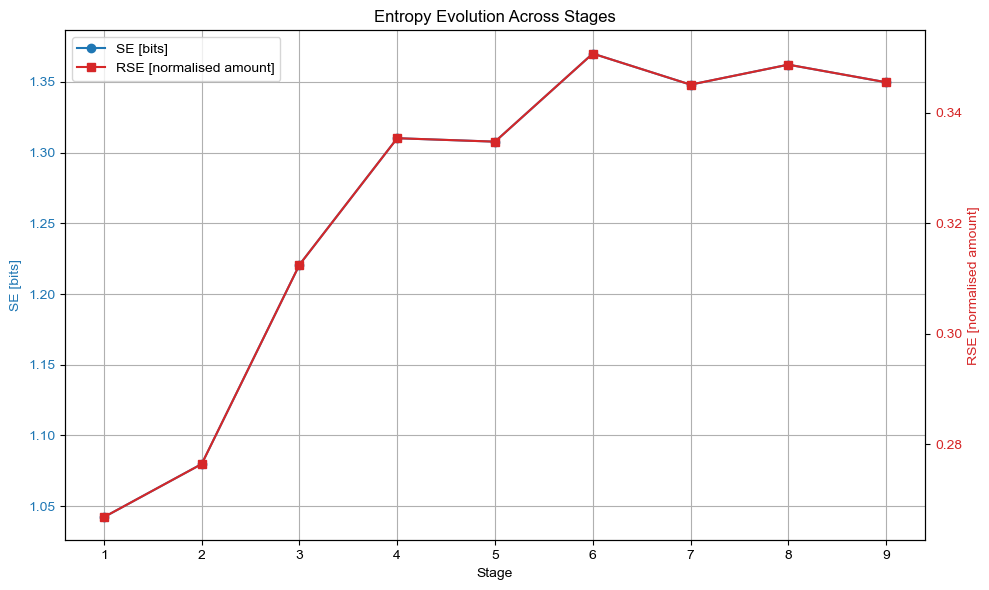

--------------------------------------------------
Let's scrutinised the role of each chemical elements in the overall statistical entropy evolution
--------------------------------------------------
Elements present in the flowsheet: ['Al', 'C', 'Ca', 'Co', 'Cu', 'F', 'Fe', 'H', 'Li', 'Mn', 'Na', 'Ni', 'O', 'P', 'S'] and their contribution to the statistical entropy evolution across stages:
 {1:          Rechberger  Relative
Element                      
Al         0.006927  0.001773
C          0.044040  0.011272
Ca         0.024777  0.006342
Co         0.019363  0.004956
Cu         0.005232  0.001339
F          0.009958  0.002549
Fe         0.000000  0.000000
H          0.198376  0.050776
Li         0.013673  0.003500
Mn         0.018526  0.004742
Na         0.070558  0.018060
Ni         0.034104  0.008729
O          0.335719  0.085930
P          0.000093  0.000024
S          0.260921  0.066785, 2:          Rechberger  Relative
Element                      
Al         0.007690  0.001

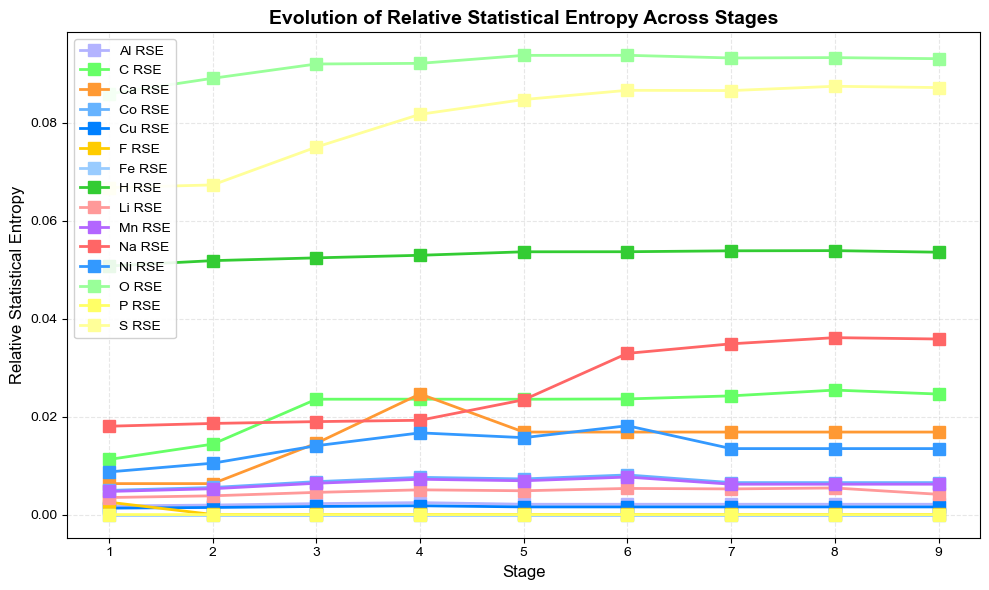

--------------------------------------------------
Get the major Stage where RSE increase.
--------------------------------------------------
Ranked by absolute RSE change:
  Stage Transition      ΔRSE  Absolute ΔRSE
1            2 → 3  0.036068       0.036068
2            3 → 4  0.022898       0.022898
4            5 → 6  0.015939       0.015939
0            1 → 2  0.009611       0.009611
5            6 → 7 -0.005620       0.005620
6            7 → 8  0.003616       0.003616
7            8 → 9 -0.003186       0.003186
3            4 → 5 -0.000625       0.000625
--------------------------------------------------
Get the major Flows that cause an entropy increase
--------------------------------------------------
=== Identical Flows between stages 2 and 3 ===
Empty DataFrame
Columns: [flow_name, flow_type, from_process, to_process]
Index: []

=== Flows Only in Stage 2 ===
   stage         flow_name flow_type         from_process  \
0      2       f_0-2_H2SO4   product           backgrou

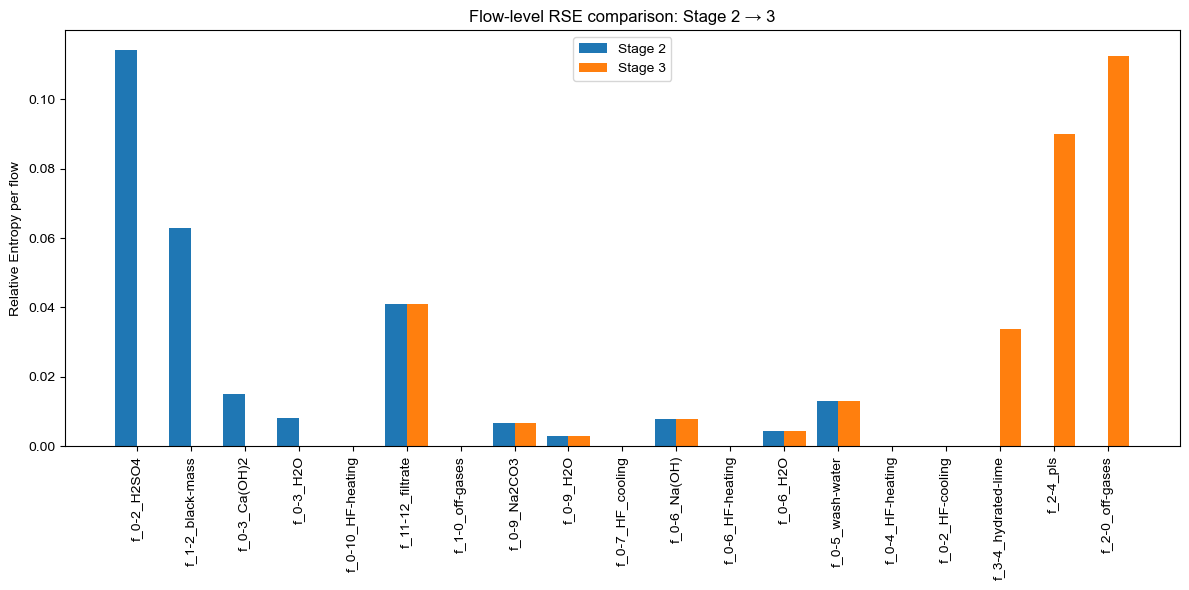

--------------------------------------------------
Analyse in general the chemical element that contribute in the stage for which the RSE has significantly increase
--------------------------------------------------


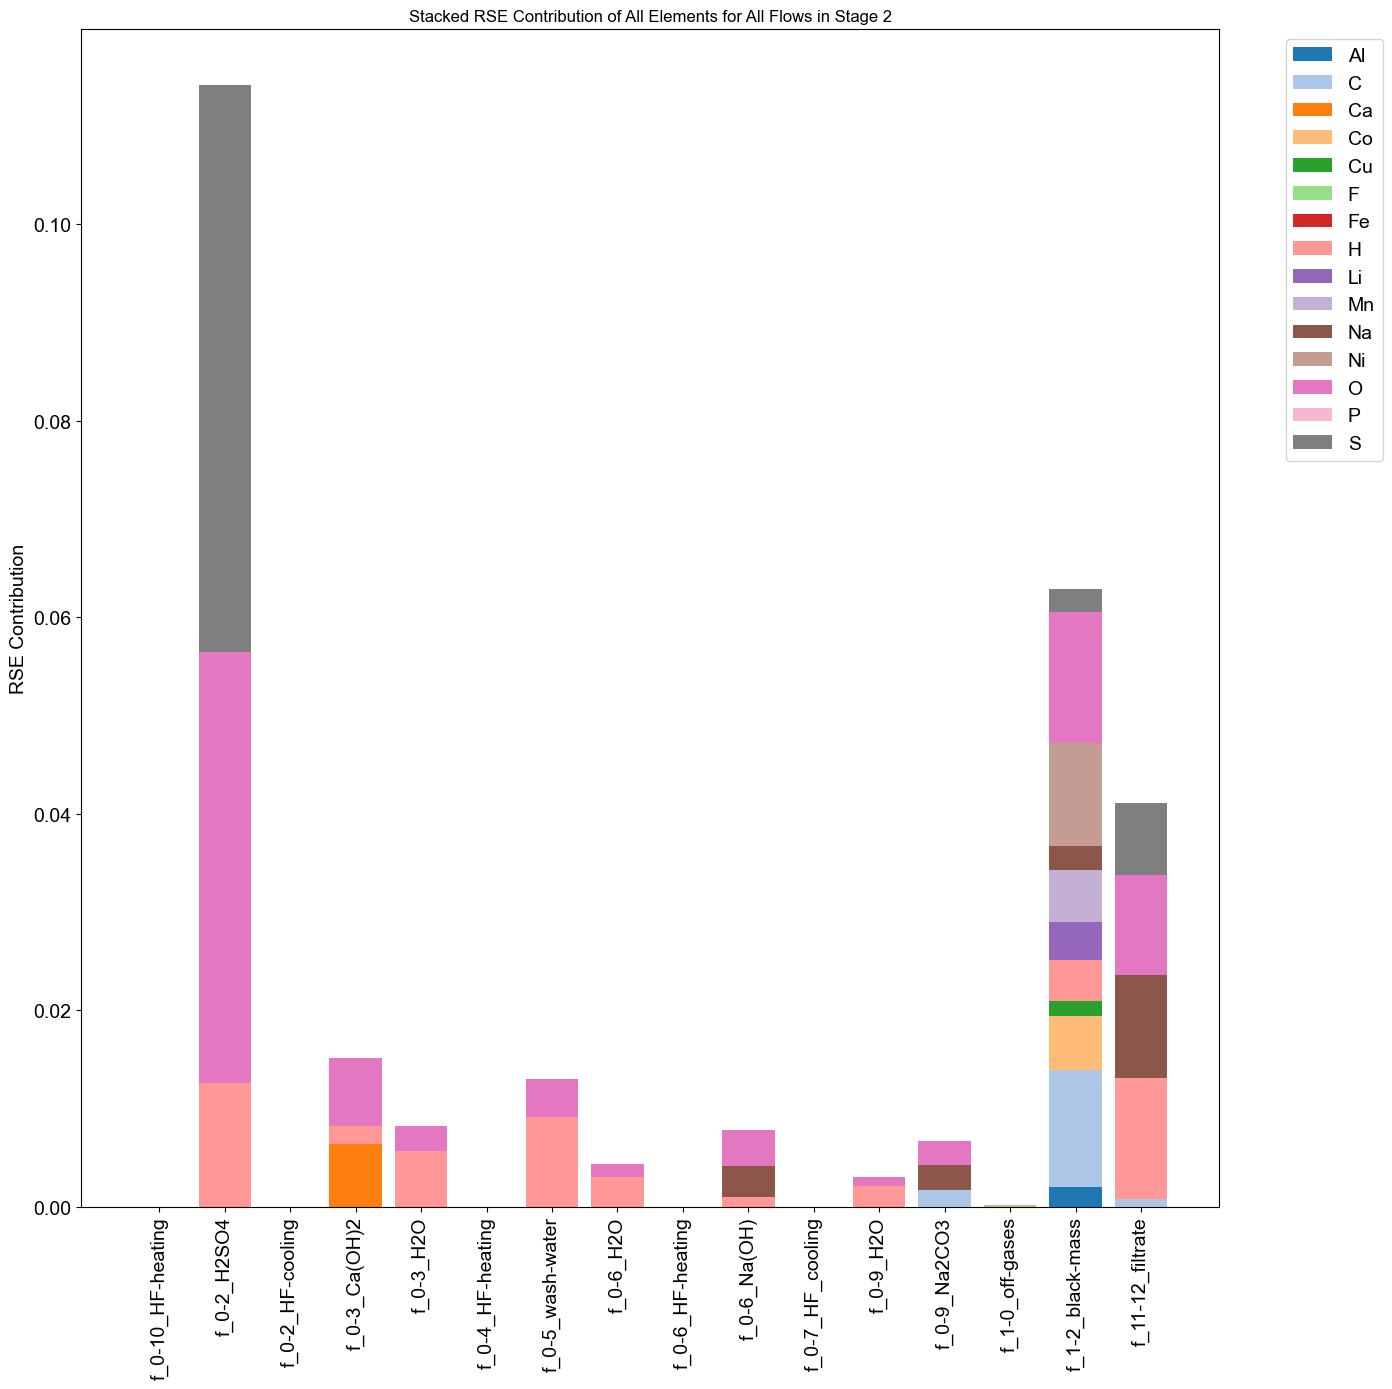

--------------------------------------------------
Get the chemical elements contribution for this stage main flow contributor
--------------------------------------------------


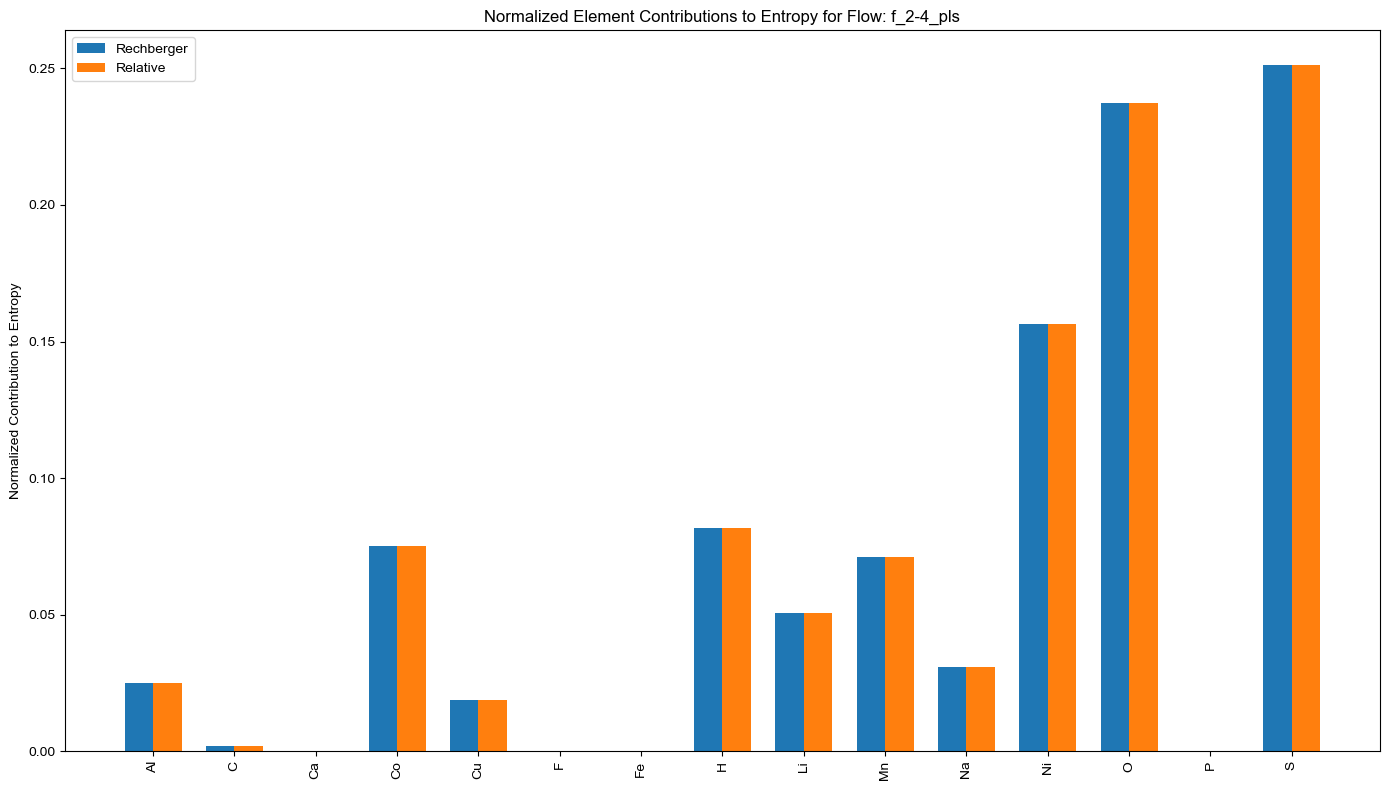

----------------------------------------------------------------------------------------------------
We can prepare a list of element of interest and then study the evolution of their entropy envolution
----------------------------------------------------------------------------------------------------
--------------------------------------------------
The contribution of Li element to the flows entropy of one stage
--------------------------------------------------


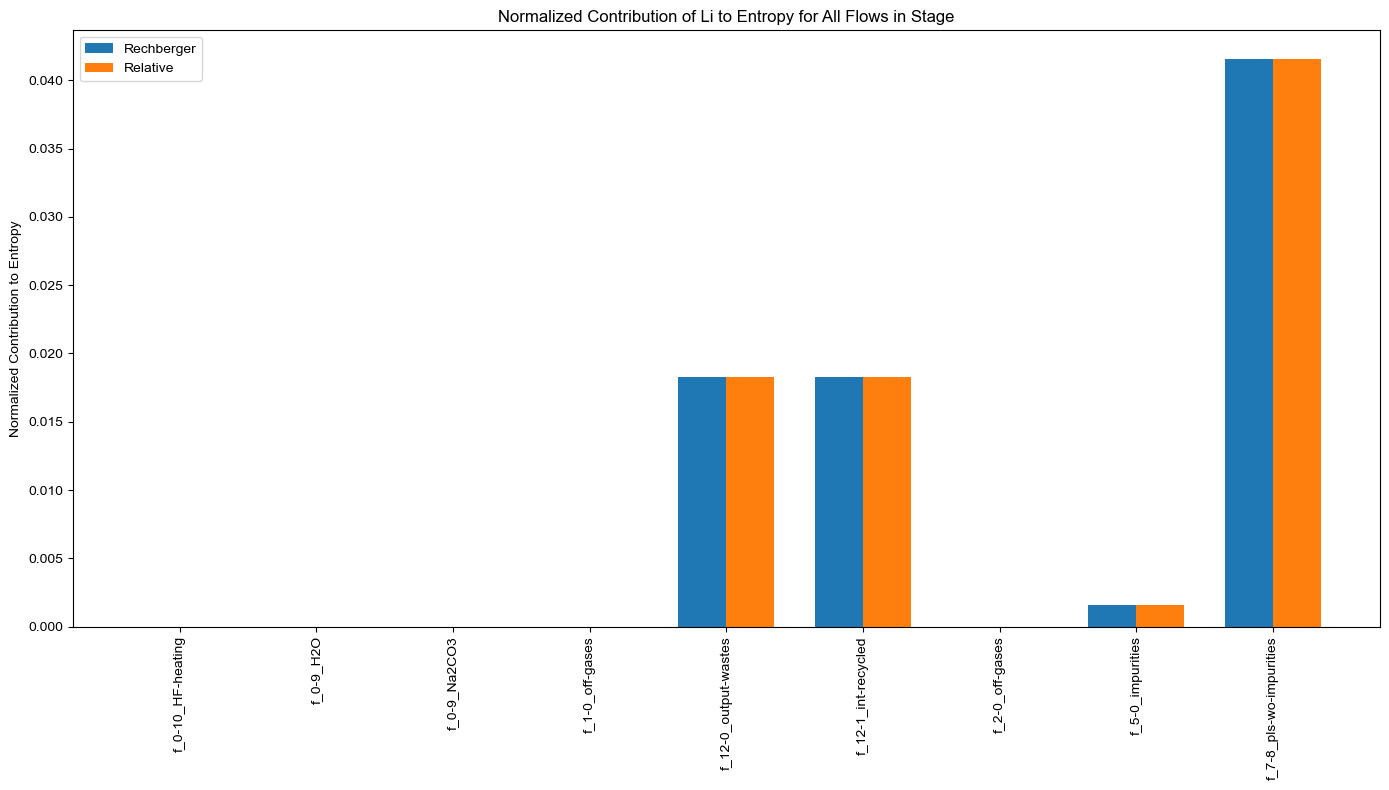

--------------------------------------------------
Also for an extended list of element of interest 
--------------------------------------------------


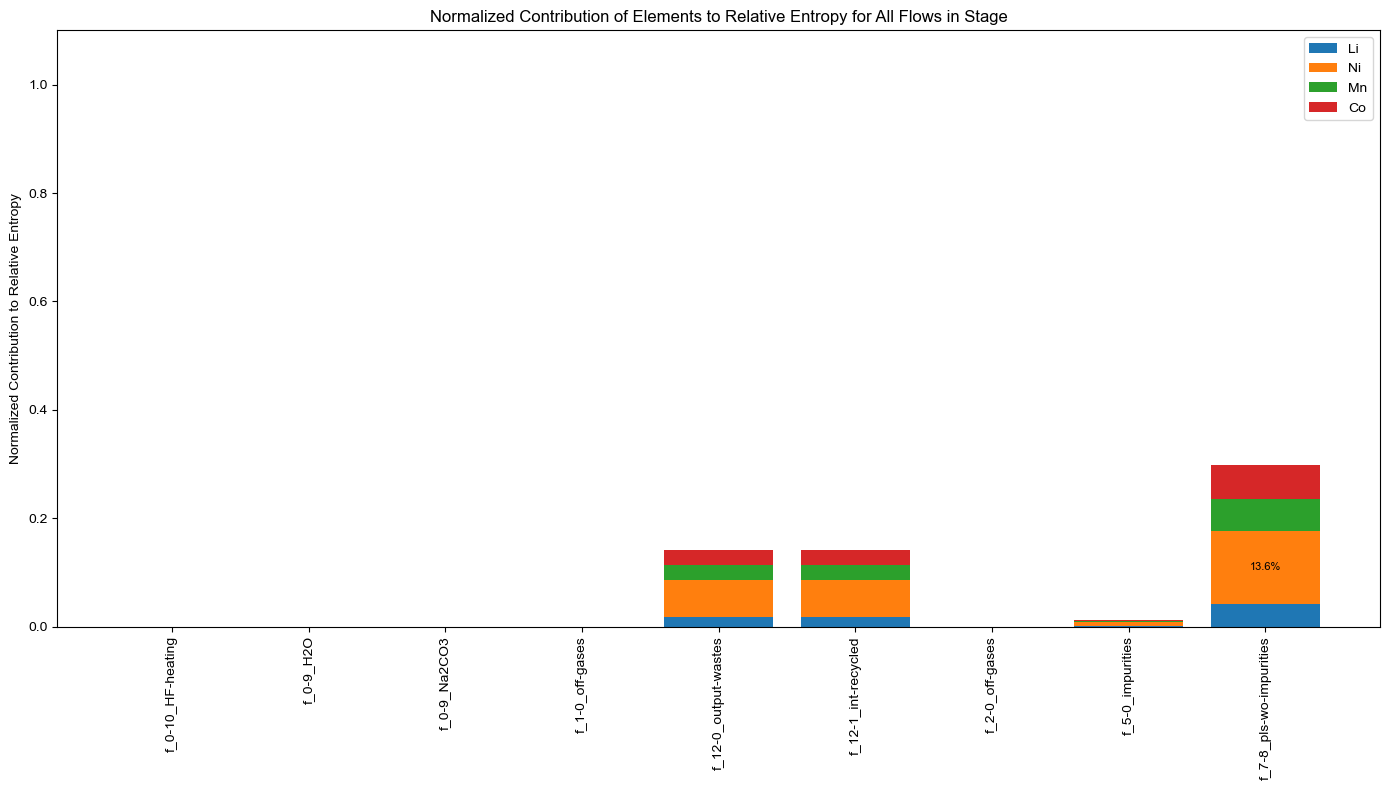

----------------------------------------------------------------------------------------------------
With these basis, we can now compute the statistical entropy value of a restricted list of element of interest that we assume diluted in a rest fraction, that we don't want to study the efforts to recover the variety of other elements inside.
----------------------------------------------------------------------------------------------------


In [22]:
# Step 1: Compute entropy for all stages
all_stage_s_dfs = compute_all_stages_entropy(stage_dfs)

# Step 2: Summarise the entropy results
summary_df = summarize_entropy(all_stage_s_dfs)  

# Step 3: Plot the results
print("-"*50)
print("Visual observation of change of Relative and Statistical entropy value across stages.")
print("-"*50)
plot_entropy(summary_df)  # Pass the DataFrame

# Step 3bis: Plot the results by elements
print("-"*50)
print("Let's scrutinised the role of each chemical elements in the overall statistical entropy evolution")
print("-"*50)
element_entropy_dfs = compute_element_entropy_across_stages(stage_dfs)
elements = ['Al',
 'C',
 'Ca',
 'Co',
 'Cu',
 'F',
 'Fe',
 'H',
 'Li',
 'Mn',
 'Na',
 'Ni',
 'O',
 'P',
 'S']
# ["Li", "Ni", "Mn", "Co"] # , "O"]
# elements = get_unique_elements(stage_dfs)
print(f"Elements present in the flowsheet: {elements} and their contribution to the statistical entropy evolution across stages:\n {element_entropy_dfs}")
plot_element_entropy_evolution(element_entropy_dfs, elements)

# Step 4: Get the differences of RSE
diff_df = compute_rse_differences(all_stage_s_dfs)

print("-"*50)
print("Get the major Stage where RSE increase.")
print("-"*50)

# Step 5: Rank by absolute ΔRSE (largest changes first)
ranked_by_abs = diff_df.sort_values("Absolute ΔRSE", ascending=False)
print("Ranked by absolute RSE change:")
print(ranked_by_abs[["Stage Transition", "ΔRSE", "Absolute ΔRSE"]])

print("-"*50)
print("Get the major Flows that cause an entropy increase")
print("-"*50)

# ⚠️ Step 6: Choose wisely a pair with a large ΔRSE ⚠️
stage_a, stage_b = 2, 3  # Example: comparing Stage 2 and Stage 3

flows_comparison_results = compare_stages(stage_dfs[stage_a], stage_dfs[stage_b])
print(f"=== Identical Flows between stages {stage_a} and {stage_b} ===")
print(flows_comparison_results['identical'])

print(f"\n=== Flows Only in Stage {stage_a} ===")
print(flows_comparison_results['only_in_df1'])

print(f"\n=== Flows Only in Stage {stage_b} ===")
print(flows_comparison_results['only_in_df2'])

print(f"\n=== Flows with Differences between stages {stage_a} and {stage_b} ===")
print(flows_comparison_results['differences'])

# Step 7: Get the df and plot the relative statistical entropy differences
merged_df = compare_flows_between_stages(all_stage_s_dfs, stage_a, stage_b)
plot_flow_rse_differences(merged_df, stage_a, stage_b)

print("-"*50)
print("Analyse in general the chemical element that contribute in the stage for which the RSE has significantly increase")
print("-"*50)

# Step 8: Plot stacked RSE contributions for all elements in a stage
plot_stacked_elements_rse_contributions_for_stage(stage_dfs[stage_a], stage_key=stage_a)


print("-"*50)
print("Get the chemical elements contribution for this stage main flow contributor")
print("-"*50)

# Step 9: get the elements' contribution to the statistical entropy of the flow
plot_element_contributions_per_flow(stage_dfs[stage_b], "f_2-4_pls")

print("-"*100)
print("We can prepare a list of element of interest and then study the evolution of their entropy envolution")
print("-"*100)

# We can also focus one element contribution per stage
print("-"*50)
element = "Li"
print(f"The contribution of {element} element to the flows entropy of one stage")
print("-"*50)
plot_an_element_contributions_for_stage(stage_dfs[6], element)


print("-"*50)
print("Also for an extended list of element of interest ")
print("-"*50)

# We can also focus a list of element
elements = ["Li", "Ni", "Mn", "Co"]
plot_elements_contributions_for_stage(stage_dfs[6], elements, min_contribution=0.1)

print("-"*100)
print("With these basis, we can now compute the statistical entropy value of a restricted list of element of interest that we assume diluted in a rest fraction, that we don't want to study the efforts to recover the variety of other elements inside.")
print("-"*100)

Elements present in the flowsheet: ['Al', 'C', 'Ca', 'Co', 'Cu', 'F', 'Fe', 'H', 'Li', 'Mn', 'Na', 'Ni', 'O', 'P', 'S'] and their contribution to the statistical entropy evolution across stages:
 {1:          Rechberger  Relative
Element                      
Al         0.006927  0.001773
C          0.044040  0.011272
Ca         0.024777  0.006342
Co         0.019363  0.004956
Cu         0.005232  0.001339
F          0.009958  0.002549
Fe         0.000000  0.000000
H          0.198376  0.050776
Li         0.013673  0.003500
Mn         0.018526  0.004742
Na         0.070558  0.018060
Ni         0.034104  0.008729
O          0.335719  0.085930
P          0.000093  0.000024
S          0.260921  0.066785, 2:          Rechberger  Relative
Element                      
Al         0.007690  0.001968
C          0.056265  0.014402
Ca         0.024775  0.006341
Co         0.021693  0.005552
Cu         0.005758  0.001474
F          0.000164  0.000042
Fe         0.000000  0.000000
H          0.202

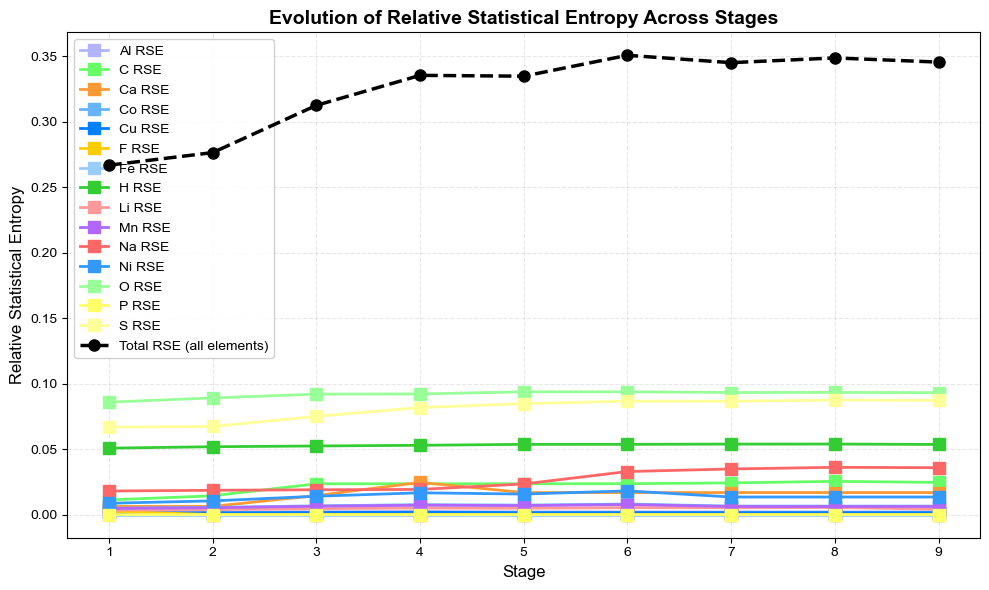

In [23]:
elements = ['Al',
 'C',
 'Ca',
 'Co',
 'Cu',
 'F',
 'Fe',
 'H',
 'Li',
 'Mn',
 'Na',
 'Ni',
 'O',
 'P',
 'S']
# ["Li", "Ni", "Mn", "Co"] # , "O"]
# elements = get_unique_elements(stage_dfs)
print(f"Elements present in the flowsheet: {elements} and their contribution to the statistical entropy evolution across stages:\n {element_entropy_dfs}")
plot_element_entropy_evolution(element_entropy_dfs, elements, plot_total=True)

## 📈 Analysis, list of elements

--------------------------------------------------
Visual observation of change of Relative and Statistical entropy value across stages for this list of element of interest
--------------------------------------------------


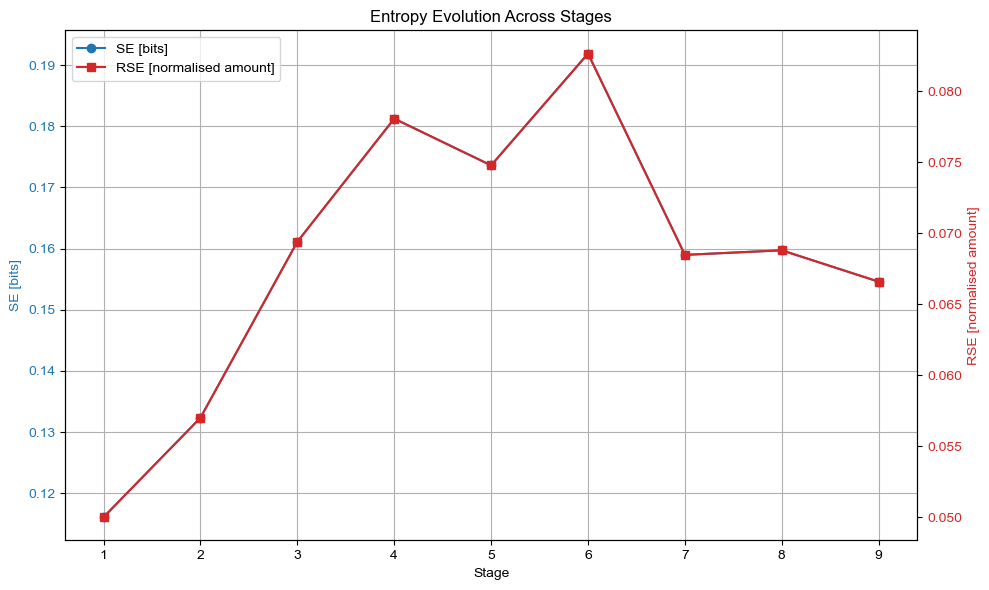

--------------------------------------------------
Let's scrutinised the role of each chemical elements in the overall statistical entropy evolution
--------------------------------------------------
This is the entropy of stages with inclusion of a rest fraction and selection of list of chemical element of interest: ['Li', 'Ni', 'Mn', 'Co', 'Rest']
 {1:          Rechberger  Relative
Element                      
Al         0.006927  0.001773
C          0.044040  0.011272
Ca         0.024777  0.006342
Co         0.019363  0.004956
Cu         0.005232  0.001339
F          0.009958  0.002549
Fe         0.000000  0.000000
H          0.198376  0.050776
Li         0.013673  0.003500
Mn         0.018526  0.004742
Na         0.070558  0.018060
Ni         0.034104  0.008729
O          0.335719  0.085930
P          0.000093  0.000024
S          0.260921  0.066785, 2:          Rechberger  Relative
Element                      
Al         0.007690  0.001968
C          0.056265  0.014402
Ca       

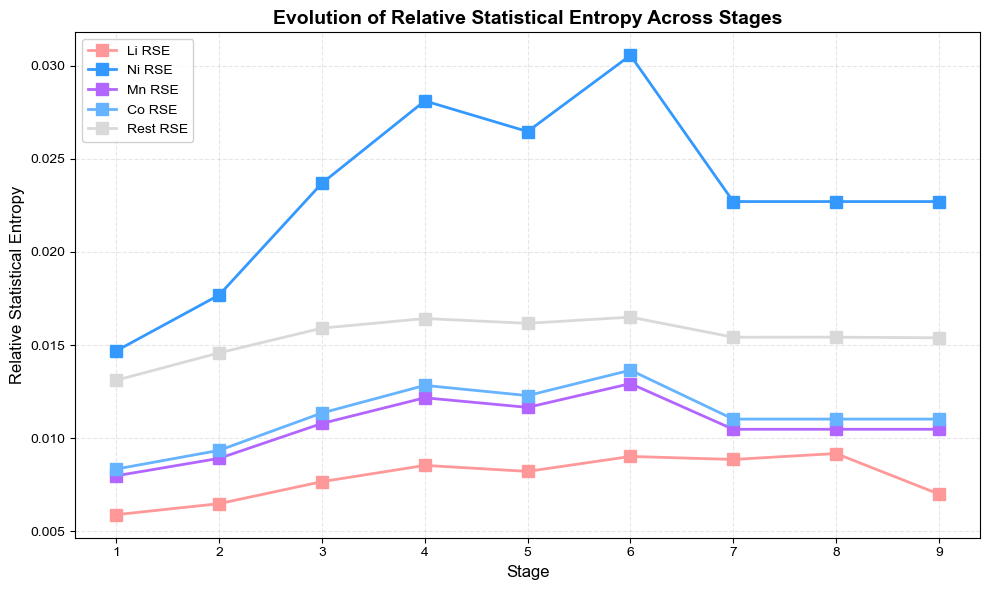

----------------------------------------------------------------------------------------------------
Follow the next steps of the general analysis
----------------------------------------------------------------------------------------------------
--------------------------------------------------
Get the major Stage where RSE increase.
--------------------------------------------------
Ranked by absolute RSE change:
  Stage Transition      ΔRSE  Absolute ΔRSE
5            6 → 7 -0.014174       0.014174
1            2 → 3  0.012394       0.012394
2            3 → 4  0.008669       0.008669
4            5 → 6  0.007872       0.007872
0            1 → 2  0.006999       0.006999
3            4 → 5 -0.003291       0.003291
7            8 → 9 -0.002209       0.002209
6            7 → 8  0.000321       0.000321
--------------------------------------------------
Get the major Flows that cause an entropy increase
--------------------------------------------------


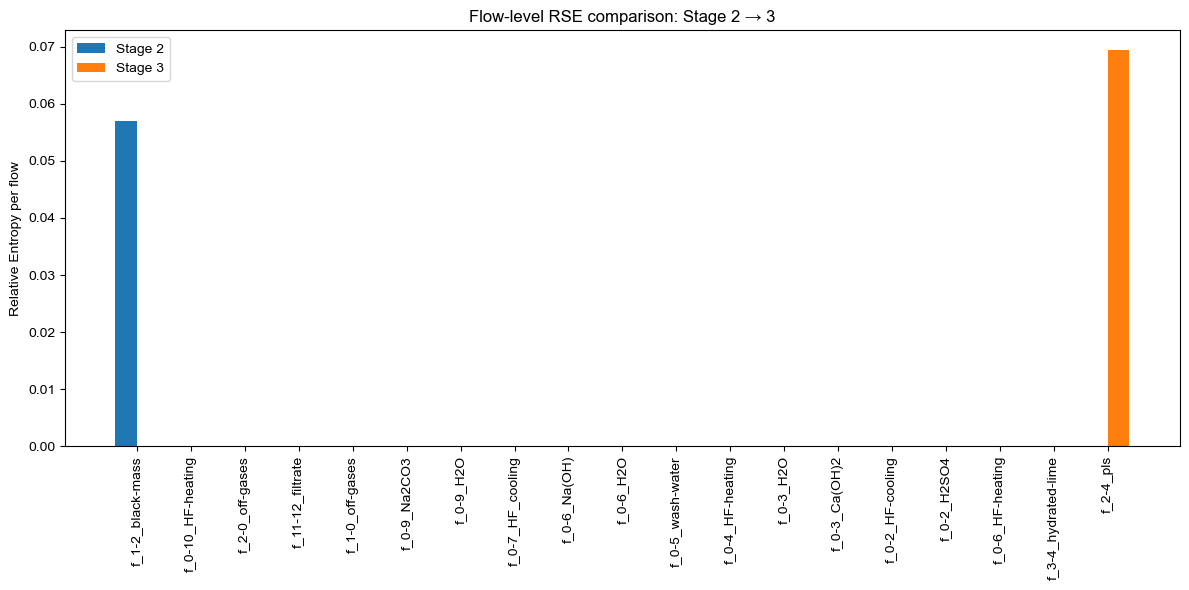

--------------------------------------------------
Analyse in general the chemical element that contribute in the stage for which the RSE has significantly increase
--------------------------------------------------


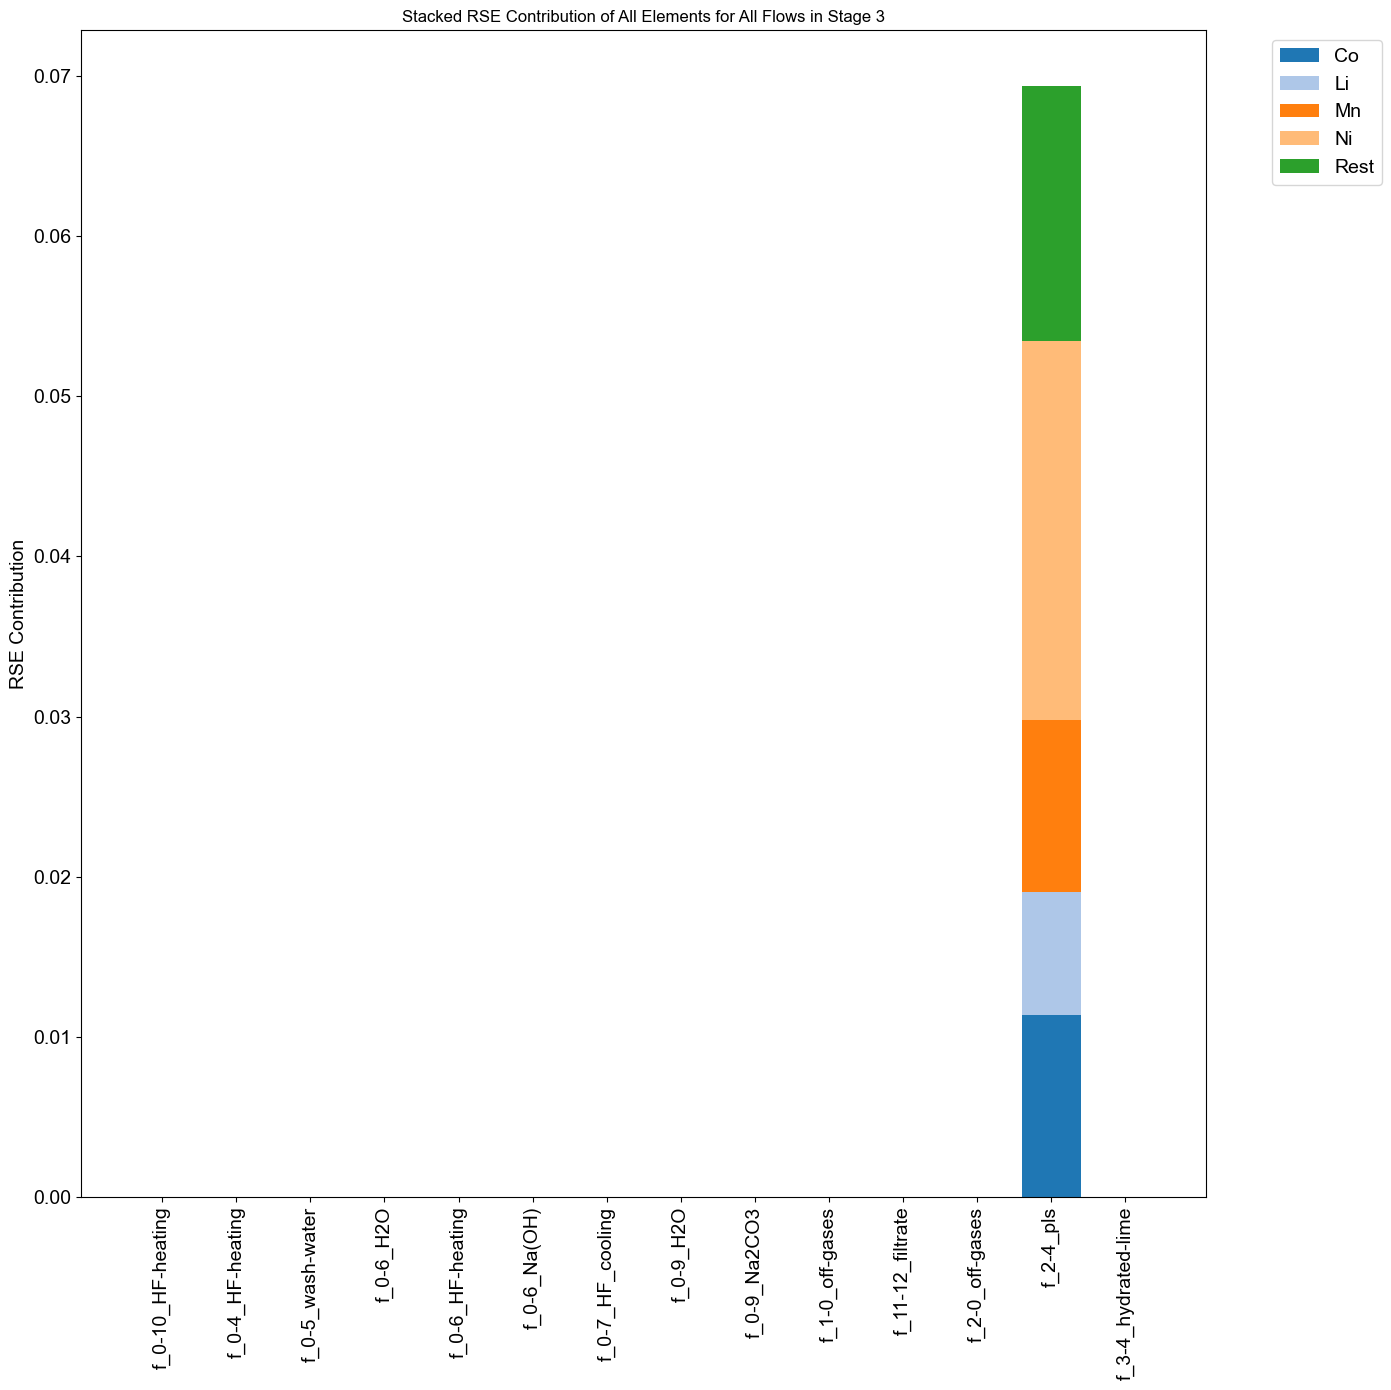

--------------------------------------------------
Get the chemical elements contribution for this stage main flow contributor
--------------------------------------------------


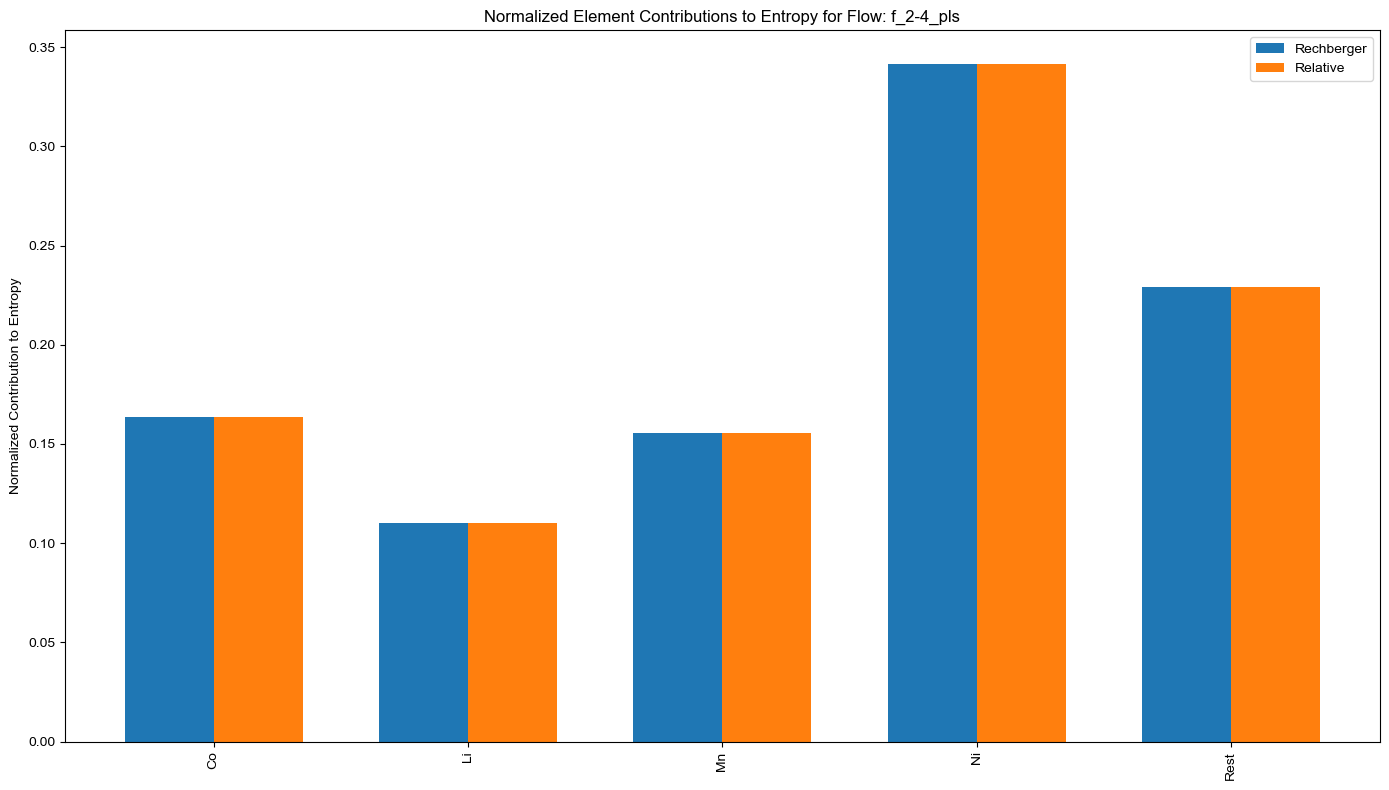

----------------------------------------------------------------------------------------------------
We can prepare a list of element of interest and then study the evolution of their entropy envolution
----------------------------------------------------------------------------------------------------
--------------------------------------------------
The contribution of one element to the flows entropy of one stage
--------------------------------------------------


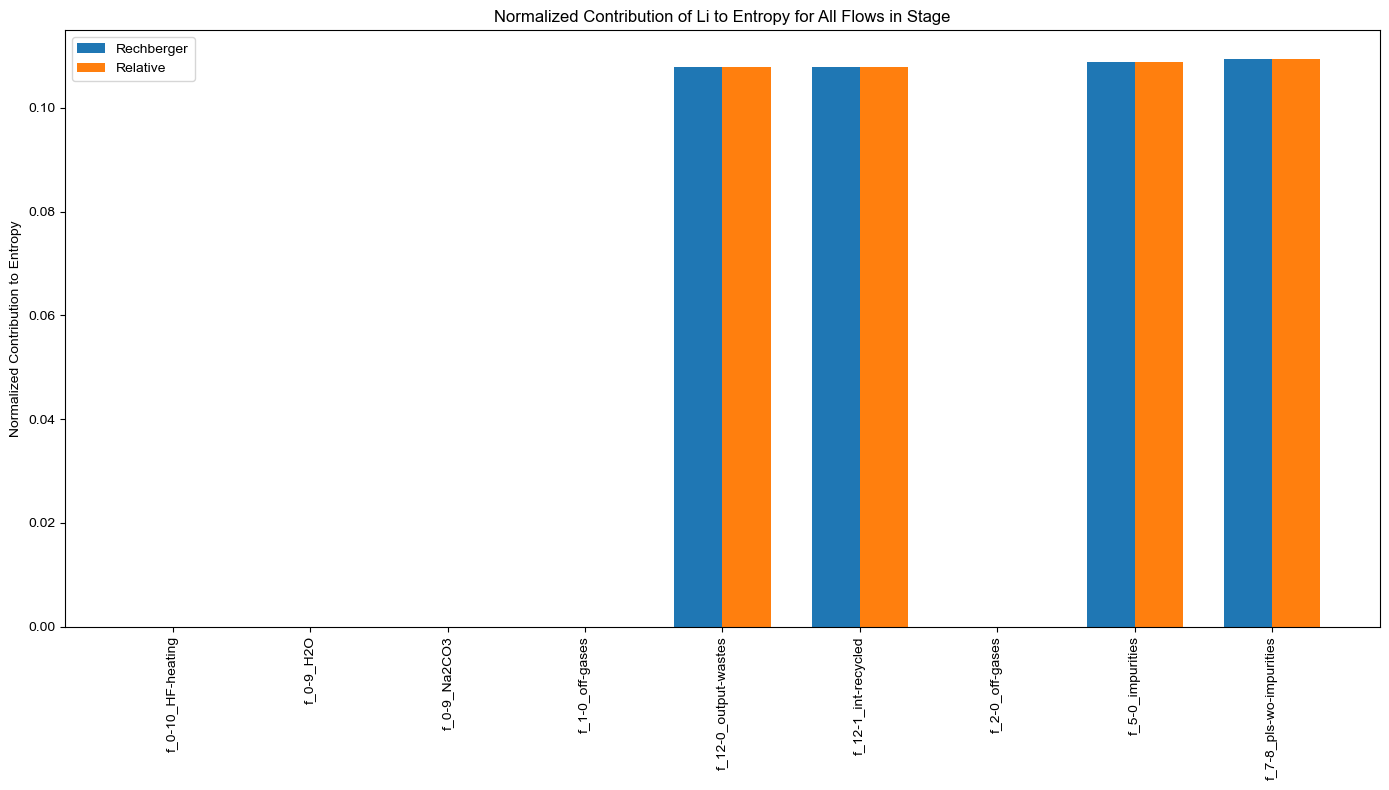

--------------------------------------------------
Also for an extended list of element of interest 
--------------------------------------------------


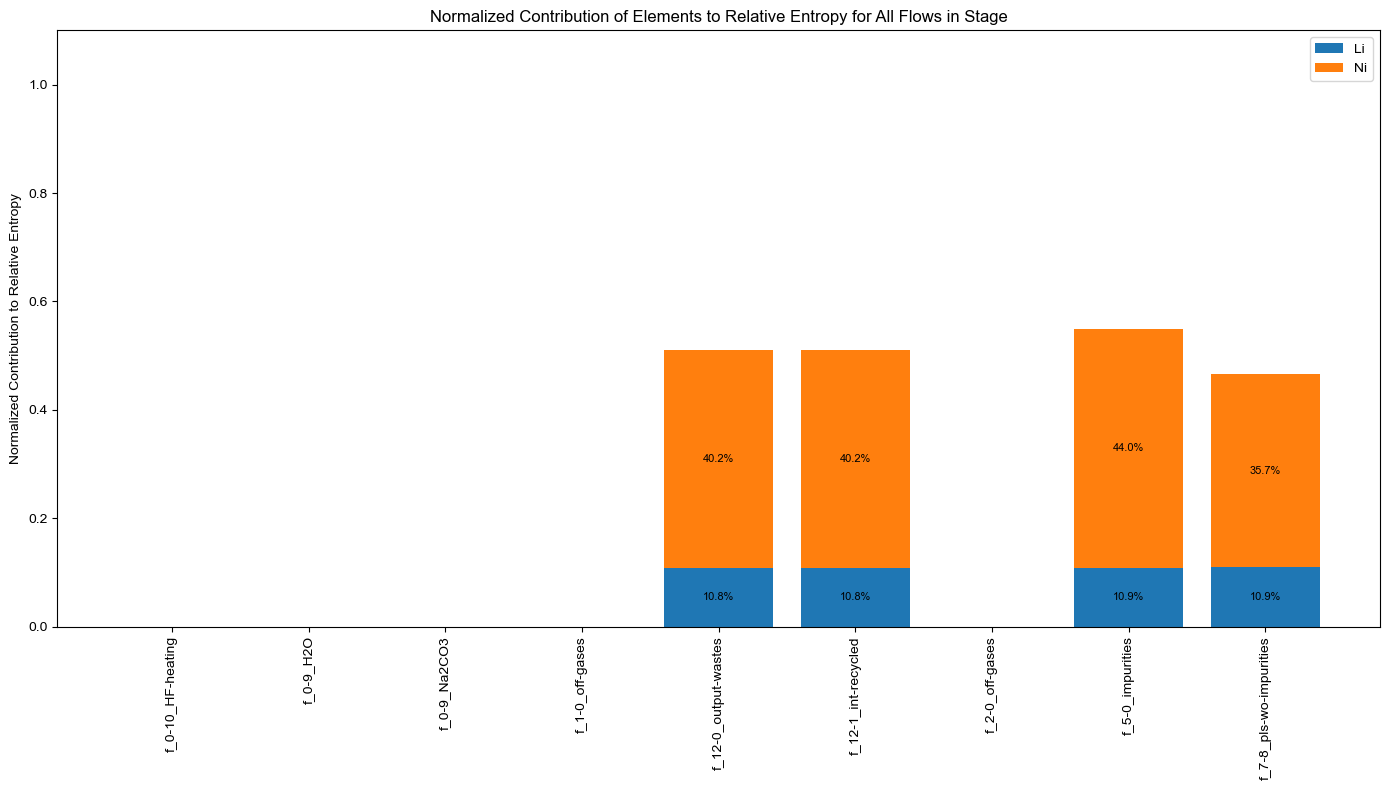

----------------------------------------------------------------------------------------------------
Over, congrates 🏆.
----------------------------------------------------------------------------------------------------


In [24]:
# Step 1: Define elements of interest



elements_of_interest = ["Li", "Ni", "Mn", "Co"] #, "Rest"]

# Step 2: Group elements of interest in the stage_dfs
restricted_stage_dfs = group_elements_of_interest(stage_dfs, elements_of_interest)

elements_of_interest = get_unique_elements(restricted_stage_dfs)

# Step 1bis: Compute entropy for all stages
all_stage_s_dfs = compute_all_stages_entropy(restricted_stage_dfs)

# Step 2bis: Summarise the entropy results
summary_df = summarize_entropy(all_stage_s_dfs)  

# Step 3: Plot the results
print("-"*50)
print("Visual observation of change of Relative and Statistical entropy value across stages for this list of element of interest")
print("-"*50)
plot_entropy(summary_df) 

# in restricted stage dfs, we can also plot the evolution of the RSE for each element of interest across stages
elements =  ["Li", "Ni", "Mn", "Co", "Rest"]
print("-"*50)
print("Let's scrutinised the role of each chemical elements in the overall statistical entropy evolution")
print("-"*50)
strategic_element_entropy_dfs = compute_element_entropy_across_stages(restricted_stage_dfs)
print(f"This is the entropy of stages with inclusion of a rest fraction and selection of list of chemical element of interest: {elements}\n {element_entropy_dfs}")
plot_element_entropy_evolution(strategic_element_entropy_dfs, elements)

print("-"*100)
print("Follow the next steps of the general analysis")
print("-"*100)

# Step 4: Get the differences of RSE
diff_df = compute_rse_differences(all_stage_s_dfs)

print("-"*50)
print("Get the major Stage where RSE increase.")
print("-"*50)

# Step 5: Rank by absolute ΔRSE (largest changes first)
ranked_by_abs = diff_df.sort_values("Absolute ΔRSE", ascending=False)
print("Ranked by absolute RSE change:")
print(ranked_by_abs[["Stage Transition", "ΔRSE", "Absolute ΔRSE"]])

print("-"*50)
print("Get the major Flows that cause an entropy increase")
print("-"*50)

# Step 6: Choose wisely a pair with a large ΔRSE
stage_a, stage_b = 2, 3  # Example: comparing Stage 2 and Stage 3

# Step 7: Get the df and plot the relative statistical entropy differences
merged_df = compare_flows_between_stages(all_stage_s_dfs, stage_a, stage_b)
plot_flow_rse_differences(merged_df, stage_a, stage_b)

print("-"*50)
print("Analyse in general the chemical element that contribute in the stage for which the RSE has significantly increase")
print("-"*50)

# Step 8: Plot stacked RSE contributions for all elements in a stage
plot_stacked_elements_rse_contributions_for_stage(restricted_stage_dfs[stage_b], stage_key=stage_b)


print("-"*50)
print("Get the chemical elements contribution for this stage main flow contributor")
print("-"*50)

# Step 9: get the elements' contribution to the statistical entropy of the flow
plot_element_contributions_per_flow(restricted_stage_dfs[stage_b], "f_2-4_pls")

print("-"*100)
print("We can prepare a list of element of interest and then study the evolution of their entropy envolution")
print("-"*100)

# We can also focus one element contribution per stage
print("-"*50)
print("The contribution of one element to the flows entropy of one stage")
print("-"*50)
element = "Li"
plot_an_element_contributions_for_stage(restricted_stage_dfs[6], element)


print("-"*50)
print("Also for an extended list of element of interest ")
print("-"*50)

# We can also focus on a more restrictive list of element
elements = ["Li", "Ni"]
plot_elements_contributions_for_stage(restricted_stage_dfs[6], elements, min_contribution=0.1)

print("-"*100)
print("Over, congrates 🏆.")
print("-"*100)

Elements present in the flowsheet: ['Li', 'Mn', 'Co', 'Ni', 'Rest'] and their contribution to the statistical entropy evolution across stages:
 {1:          Rechberger  Relative
Element                      
Al         0.006927  0.001773
C          0.044040  0.011272
Ca         0.024777  0.006342
Co         0.019363  0.004956
Cu         0.005232  0.001339
F          0.009958  0.002549
Fe         0.000000  0.000000
H          0.198376  0.050776
Li         0.013673  0.003500
Mn         0.018526  0.004742
Na         0.070558  0.018060
Ni         0.034104  0.008729
O          0.335719  0.085930
P          0.000093  0.000024
S          0.260921  0.066785, 2:          Rechberger  Relative
Element                      
Al         0.007690  0.001968
C          0.056265  0.014402
Ca         0.024775  0.006341
Co         0.021693  0.005552
Cu         0.005758  0.001474
F          0.000164  0.000042
Fe         0.000000  0.000000
H          0.202652  0.051870
Li         0.015047  0.003851
Mn      

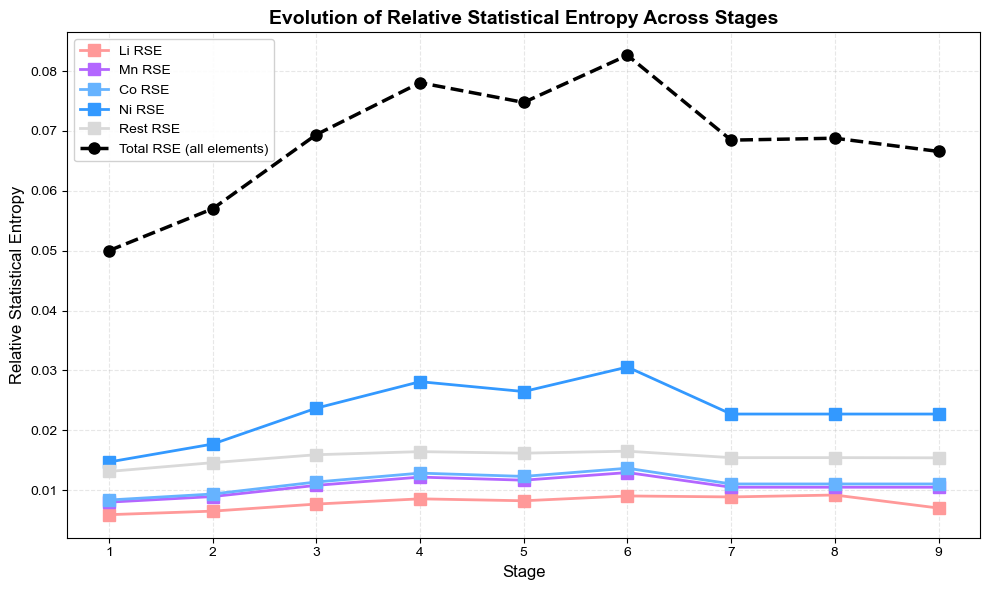

In [25]:
strategic_elements = [
 'Li',
 'Mn',
 'Co',
 'Ni',
 'Rest'
 ]
# ["Li", "Ni", "Mn", "Co"] # , "O"]
# elements = get_unique_elements(stage_dfs)
print(f"Elements present in the flowsheet: {strategic_elements} and their contribution to the statistical entropy evolution across stages:\n {element_entropy_dfs}")
plot_element_entropy_evolution(strategic_element_entropy_dfs, strategic_elements, plot_total=True)

# 🔚 end